In [1]:
import joblib
import h5py
import numpy as np
from SPIDER.commons.utils import save, load
from SPIDER.continuous.library import *
import gc
from SPIDER.continuous.process_library_terms import *
from SPIDER.commons.identify_models import *
from SPIDER.commons.sparse_reg_bf import AIC, Initializer, ModelIterator, Residual, Scaler, Threshold, sparse_reg_bf
import copy
import jax
import jax.numpy as jnp
from jax_cfd.base import boundaries, grids, pressure, finite_differences as fd
import jax_cfd.base as cfd
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral
import numpy as np
#import xarray 
#import xarray as xr
import dataclasses
import time
jax.config.update("jax_enable_x64", True)
import numpy as np
import os, joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from numpy.polynomial.chebyshev import chebvander

import contextlib
import joblib
from tqdm import tqdm

@contextlib.contextmanager
def tqdm_joblib(tqdm_object):
    """Context manager to patch joblib to report into tqdm progress bar given as argument"""
    class TqdmBatchCompletionCallback(joblib.parallel.BatchCompletionCallBack):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    old_batch_callback = joblib.parallel.BatchCompletionCallBack
    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_batch_callback
        tqdm_object.close()

/storage/home/hcoda1/2/ashelestov3/.conda/envs/SPIDER/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# --- NEW CELL (Call this 'Cell 2 - New') ---
# Run this cell INSTEAD of the old cells 2, 3, and 4.

print("Loading preprocessed arrays from .npz file...")

# Path to the file you just saved
load_path = '/storage/scratch1/2/ashelestov3/preprocessed_paper_data.npz'

# Load the data from the .npz file
data = np.load(load_path)
print("loaded - processing")
# Re-create your variables from the saved data
V = data['U']
U = data['V']
P = data['P']
B = data['B']
W = data['W']
x = data['x']
y = data['y']
t = data['t']
print(y,y[1]-y[0],y[201]-y[200])
y=np.linspace(0,1,num=1536)

print(y,y[1]-y[0],y[201]-y[200])
del(data)
# IMPORTANT: You must also re-define the parameters from your old Cell 3,
# as the rest of your notebook depends on them.
size_x = 4096
size_y = 1536
inner_steps = 1
outer_steps = t.shape[0]

Lx =  4
Ly = 1
Nx = size_x
Ny = size_y
Nt = outer_steps
# Calculate dx/dy from the actual new coordinate arrays
dx = x[1] - x[0]
dy = y[1] - y[0]
print(f"Updated dx: {dx}, dy: {dy}")
Lt = t[-1]-t[0]
dt = Lt/Nt
Rayleigh = 1e8
Prandtl = 1
kappa = (Rayleigh * Prandtl)**(-1/2)
print("Done loading!")
print("U shape:", U.shape)
print("P shape:", P.shape)
print("dx:", dx)
print("dt:", dt)
print(dy-Ly / (Ny - 1))

Loading preprocessed arrays from .npz file...
loaded - processing
[0.00000000e+00 6.51465798e-04 1.30293160e-03 ... 9.98697068e-01
 9.99348534e-01 1.00000000e+00] 0.0006514657980456026 0.0006514657980456195
[0.00000000e+00 6.51465798e-04 1.30293160e-03 ... 9.98697068e-01
 9.99348534e-01 1.00000000e+00] 0.0006514657980456026 0.0006514657980456195
Updated dx: 0.0009765625, dy: 0.0006514657980456026
Done loading!
U shape: (4096, 1536, 101)
P shape: (4096, 1536, 101)
dx: 0.0009765625
dt: 2.380099009900647e-05
0.0


In [3]:
import builtins
import jax
import jax.numpy as jnp
from functools import partial

# --- REPLACEMENT FILTERING FUNCTIONS (Adapted for 2D: x, y) ---

def _sigma_from_delta(delta):
    return delta / jnp.sqrt(12.0)

def _trap_weights_nonuniform(x):
    dx = jnp.diff(x)
    w_mid = 0.5 * (dx[:-1] + dx[1:])
    w0 = 0.5 * dx[0]
    wn = 0.5 * dx[-1]
    return jnp.concatenate([jnp.array([w0]), w_mid, jnp.array([wn])])

@partial(jax.jit, static_argnums=(4,))
def _convolve1d_nonuniform_gaussian(arr, coord, delta, alpha, axis):
    sigma = _sigma_from_delta(delta)
    R = alpha * delta
    n = coord.size

    # Trapezoidal weights
    wq = _trap_weights_nonuniform(coord)

    # Move axis to front for easy processing
    a = jnp.moveaxis(arr, axis, 0)  # shape: (n, ...)

    # Build the pairwise distance matrix (n, n)
    dists = coord[:, None] - coord[None, :]
    kernel = jnp.exp(-0.5 * (dists / sigma)**2)
    mask = jnp.abs(dists) <= R
    kernel = kernel * mask

    # Weighted kernel
    weighted_kernel = kernel * wq[None, :]  # shape (n, n)
    norm = weighted_kernel.sum(axis=1, keepdims=True)
    weights = weighted_kernel / norm  # normalize rows

    # Apply weights: shape (n, ...) = (n, n) @ (n, ...)
    out = jnp.tensordot(weights, a, axes=(1, 0))  # shape (n, ...)

    return jnp.moveaxis(out, 0, axis)

def trim_edges_jax(array, x=None, y=None, delta=0.0):
    """
    Trims `delta` distance from the edges of a JAX array and coordinates.
    Adapted for 2D inputs (x, y).
    """
    def get_valid_indices(coord):
        return jnp.where((coord >= coord[0] + delta) & (coord <= coord[-1] - delta))[0]

    slices = []
    new_coords = []

    # Iterate over x and y only (matching array shape order)
    for coord in (x, y):
        if coord is not None:
            idx = get_valid_indices(coord)
            if len(idx) > 0:
                start = int(idx[0])
                end = int(idx[-1]) + 1
                slices.append(builtins.slice(start, end))
                new_coords.append(coord[start:end])
            else:
                # Fallback if delta trims everything
                slices.append(builtins.slice(None))
                new_coords.append(coord)
        else:
            slices.append(builtins.slice(None))
            new_coords.append(None)

    # Trim array using tuple of slices
    # The array has a time dimension at the end, keep it full
    slices.append(builtins.slice(None)) 
    trimmed_array = array[tuple(slices)]

    return trimmed_array, *new_coords

def gaussian_filter_2d_finite_support_over_time(field, x, y, delta, alpha):
    """
    Applies Gaussian filter along x, y axes at each time slice.
    field: (Nx, Ny, Nt)
    """
    print(field.shape)
    dx = float(x[1] - x[0])
    dy = float(y[1] - y[0])
    
    # ADDED: Pre-calculate constant kernels
    kernel_x = _get_uniform_gaussian_kernel(dx, delta, alpha)
    kernel_y = _get_uniform_gaussian_kernel(dy, delta, alpha)
    def filter_single_timestep(f):
        # f has shape (Nx, Ny)
        print(f.shape)
        f = _convolve1d_uniform_edge_padded(f, kernel_x, axis=0)
        f = _convolve1d_uniform_edge_padded(f, kernel_y, axis=1)
        
        # Return the full 2D frame, NOT f[..., 0]
        return f

    # Use JAX vmap to vectorise over the Time axis (axis 2 in your data)
    # field shape is (Nx, Ny, Nt), so we map over axis 2
    result = jax.vmap(filter_single_timestep, in_axes=2, out_axes=2)(field)
    
    # Trim edges
    field_out, xp, yp = trim_edges_jax(result, x, y, delta=(alpha * (delta+1)))
    
    return field_out, xp, yp

def _get_uniform_gaussian_kernel(dx, delta, alpha):
    sigma = delta / jnp.sqrt(12.0)
    R = alpha * delta
    r_points = int(jnp.ceil(R / dx))
    xs = jnp.arange(-r_points, r_points + 1) * dx
    kernel = jnp.exp(-0.5 * (xs / sigma)**2)
    return kernel / jnp.sum(kernel)

@partial(jax.jit, static_argnums=(2,))
def _convolve1d_uniform_edge_padded(arr, kernel, axis):
    pad_width = len(kernel) // 2
    if axis == 0:
        padded = jnp.pad(arr, ((pad_width, pad_width), (0, 0)), mode='edge')
        conv_fn = jax.vmap(lambda x: jnp.convolve(x, kernel, mode='valid'))
        return conv_fn(padded.T).T
    elif axis == 1:
        padded = jnp.pad(arr, ((0, 0), (pad_width, pad_width)), mode='edge')
        conv_fn = jax.vmap(lambda x: jnp.convolve(x, kernel, mode='valid'))
        return conv_fn(padded)
    
    

# --- EXECUTION ---

# Define parameters based on your notebook variables
delta = 50 * dx
print(delta)
alpha = 3

print("Starting JAX filtering...")

# Convert numpy arrays to JAX arrays for processing
u_jax = jnp.array(U)
x_jax = jnp.array(x)
y_jax = jnp.array(y)
print(u_jax.shape)
# Run the filter
# Note: No 'z' is passed because your data is 2D
u_filt, xp, yp = gaussian_filter_2d_finite_support_over_time(u_jax, x_jax, y_jax, delta, alpha)

# If you need to filter other variables (V, P, B, W):
# v_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V), x_jax, y_jax, delta, alpha)
# p_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(P), x_jax, y_jax, delta, alpha)

print("Filtering complete.")
print("New shape:", u_filt.shape)

0.048828125
Starting JAX filtering...
(4096, 1536, 101)
(4096, 1536, 101)
(4096, 1536)
Filtering complete.
New shape: (4096, 1536, 101)


In [4]:
# --- STEP 2: Filter Remaining Variables & Calculate Stresses ---

print("Filtering remaining variables...")

# 1. Filter the primary variables (V, P, B, W)
# We use the same parameters (delta, alpha) and coordinate arrays as Step 1.
v_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V), x_jax, y_jax, delta, alpha)
p_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(P), x_jax, y_jax, delta, alpha)
b_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(B), x_jax, y_jax, delta, alpha)
w_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(W), x_jax, y_jax, delta, alpha)

# 2. Filter the product terms for Reynolds Stresses
# Mathematical requirement: Filter the products (uu, vv, uv) before subtracting the means.
print("Filtering product terms for Tau...")
uu_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U**2), x_jax, y_jax, delta, alpha)
vv_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V**2), x_jax, y_jax, delta, alpha)
uv_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U*V), x_jax, y_jax, delta, alpha)

# 3. Calculate Stresses (Tau)
# Formula: tau_ij = filtered(u_i * u_j) - filtered(u_i) * filtered(u_j)

# Convert JAX arrays back to standard Numpy arrays for final assembly
u_filt_np = np.array(u_filt)
v_filt_np = np.array(v_filt)
uu_filt_np = np.array(uu_filt)
vv_filt_np = np.array(vv_filt)
uv_filt_np = np.array(uv_filt)

tau_xx = uu_filt_np - (u_filt_np**2)
tau_yy = vv_filt_np - (v_filt_np**2)
tau_xy = uv_filt_np - (u_filt_np * v_filt_np)

# 4. Stack the full SGS stress and retain the ordinary filtered pressure.
print("Stacking final arrays...")

# Create u_bar vector: Shape (Nx, Ny, Nt, 2)
u_bar = np.stack([u_filt_np, v_filt_np], axis=3)

# Create Tau tensor: Shape (Nx, Ny, Nt, 2, 2)
# Structure: [[tau_xx, tau_xy], [tau_xy, tau_yy]]
row1 = np.stack([tau_xx, tau_xy], axis=3)
row2 = np.stack([tau_xy, tau_yy], axis=3)
tau = np.stack([row1, row2], axis=4)

# 5. Finalize other fields
p_filt = np.array(p_filt)
b_filt = np.array(b_filt)
w_filt = np.array(w_filt)

# Update coordinate arrays to the trimmed versions returned by the filter
x = np.array(xp)
y = np.array(yp)

print("Step 2 Complete.")
print(f"Final shapes -> u_bar: {u_bar.shape}, tau: {tau.shape}")

Filtering remaining variables...
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
Filtering product terms for Tau...
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
Stacking final arrays...
Step 2 Complete.
Final shapes -> u_bar: (4096, 1536, 101, 2), tau: (4096, 1536, 101, 2, 2)


In [5]:
print("filtering product terms for phi")

ub_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U * B), x_jax, y_jax, delta, alpha)
vb_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V * B), x_jax, y_jax, delta, alpha)

ub_filt_np = np.array(ub_filt)
vb_filt_np = np.array(vb_filt)

phi_x = ub_filt_np - (u_filt_np * b_filt)
phi_y = vb_filt_np - (v_filt_np * b_filt)

print("stacking")

phi = np.stack([phi_x, phi_y], axis=3)

print(f"Final shape -> phi: {phi.shape}")

filtering product terms for phi
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
stacking
Final shape -> phi: (4096, 1536, 101, 2)


In [6]:
u_bar=u_bar[50:-50,50:-50,:,:]
tau=tau[50:-50,50:-50,:,:,:]
p_filt=p_filt[50:-50,50:-50,:]
b_filt=b_filt[50:-50,50:-50,:]
w_filt=w_filt[50:-50,50:-50,:]
phi=phi[50:-50,50:-50,:,:]
x = x[50:-50]
y = y[50:-50]

print(f"Final-er shapes -> u_bar: {u_bar.shape}, tau: {tau.shape}, phi: {phi.shape}, x: {x.shape}, y: {y.shape}")

Final-er shapes -> u_bar: (3996, 1436, 101, 2), tau: (3996, 1436, 101, 2, 2), phi: (3996, 1436, 101, 2), x: (3996,), y: (1436,)


In [71]:
print(np.mean(u_filt), np.mean(v_filt))

3.008161202570671e-05 1.281911401503247e-06


In [73]:
print(phi.shape)

(3996, 1436, 101, 2)


In [8]:
#%%prun # profiling
#print(P.shape)
# u_bar components are ordered [u_x, u_z], so the vertical unit vector is [0, 1].
unit_vect = np.stack([np.zeros_like(b_filt), np.ones_like(b_filt)], axis=3)

print("--- SHAPE CHECK ---")
print(f"u_bar: {u_bar.shape}")
print(f"w_filt: {w_filt.shape}")  # Or v_bar/v_filt depending on your naming
print(f"b_filt: {b_filt.shape}")
print(f"p_filt: {p_filt.shape}")
print(f"tau: {tau.shape}")
print(f"phi: {phi.shape}")
print(f"x: {x.shape}")
print(f"y: {y.shape}")
print(f"z̄: {unit_vect.shape}")
print("-------------------")
uobs = Observable(string='u', rank=1)
pobs = Observable(string='p', rank=0)
bobs = Observable(string='b', rank=0) #?
zobs = Observable(string='z̄', rank=1)
wobs = Observable(string='w', rank=0)
Tobs = Observable(string='T', rank=2, can_commute_indices = True, antisymmetric = False)
fobs = Observable(string='ϕ', rank=1)
observables = [uobs, bobs, pobs, zobs, wobs, Tobs, fobs]#bobszobs

data_dict = {'u' : u_bar, 'b' : b_filt, 'p' : p_filt, 'z̄' : unit_vect, 'w' : w_filt, 'T' : tau, 'ϕ' : phi}
# fix random seed
np.random.seed(1)

world_size = np.array(b_filt.shape)
pad = 0

# fix random seed
np.random.seed(1)

dxs = [dx, dy, dt]

# initial setup of dataset
srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                irreps=SRDataset.all_rank2_irreps())
                #irreps=(0, 1, 2))

# Build one shared library for equation recovery and SGS closure discovery.
# Complexity 4 admits products of two first spatial derivatives.
srd.make_libraries(max_complexity=4, max_observables=2)
print(srd.libs)

--- SHAPE CHECK ---
u_bar: (3996, 1436, 101, 2)
w_filt: (3996, 1436, 101)
b_filt: (3996, 1436, 101)
p_filt: (3996, 1436, 101)
tau: (3996, 1436, 101, 2, 2)
phi: (3996, 1436, 101, 2)
x: (3996,)
y: (1436,)
z̄: (3996, 1436, 101, 2)
-------------------
{Rank 0: LibraryData(terms=[T_αα, T_αα · b, T_αα · p, T_αα · w, ∂t T_αα, b, b · b, b · b · b, b · b · p, b · b · w, b · ∂t b, b · p, b · p · p, b · p · w, b · ∂t p, b · u_α · u_α, b · u_α · z̄_α, b · u_α · ϕ_α, b · ∂α u_α, b · w, b · w · w, b · ∂t w, b · z̄_α · z̄_α, b · z̄_α · ϕ_α, b · ∂α z̄_α, b · ϕ_α · ϕ_α, b · ∂α ϕ_α, ∂α b · u_α, ∂α b · z̄_α, ∂α b · ϕ_α, ∂α² b, ∂t b, ∂t b · p, ∂t b · w, ∂t² b, p, p · p, p · p · p, p · p · w, p · ∂t p, p · u_α · u_α, p · u_α · z̄_α, p · u_α · ϕ_α, p · ∂α u_α, p · w, p · w · w, p · ∂t w, p · z̄_α · z̄_α, p · z̄_α · ϕ_α, p · ∂α z̄_α, p · ϕ_α · ϕ_α, p · ∂α ϕ_α, ∂α p · u_α, ∂α p · z̄_α, ∂α p · ϕ_α, ∂α² p, ∂t p, ∂t p · w, ∂t² p, u_α · u_α, u_α · u_α · w, u_α · ∂t u_α, u_α · w · z̄_α, u_α · w · ϕ_α, u_α · ∂α w, 

In [9]:
remove_terms = {
    "z̄_β · ∂α z̄_β",
    "∂t b · z̄_α",
    "z̄_α · z̄_β · z̄_β",
    "z̄_β · z̄_β · ϕ_α",
    "z̄_β · ∂α z̄_β",
    "∂α z̄_β"
}

def is_unwanted(t):
    return (str(t) in remove_terms)

for irrep in srd.irreps:
    lib = srd.libs[irrep]
    original_len = len(lib.terms)
    
    # Filter the terms
    lib.terms = [t for t in lib.terms if not is_unwanted(t)]
    
    new_len = len(lib.terms)
    print(f"Irrep {irrep}: Removed {original_len - new_len} terms. Remaining: {new_len}")
    print(irrep, ":", len(srd.libs[irrep].terms))

import os
 
# Logical cores (including hyperthreading)
num_cores = os.cpu_count()
print(f"Logical CPU cores available: {num_cores}")
largest_library = max(len(srd.libs[irrep].terms) for irrep in srd.irreps)
Ndomainz = largest_library * 10
num_processorz = max(1, num_cores - 4)
Ndomainz_rounded = num_processorz * int(np.ceil(Ndomainz / num_processorz))
print("Largest library:", largest_library)
print(num_processorz)
print(Ndomainz_rounded)
dom_width = 64 #scale for res
dom_time = 40 #previously 20 (without interpolation)
pad = 0
srd.make_domains(ndomains=Ndomainz_rounded, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=16, qmax=0)
srd.set_LT_scale(L=dx*dom_width, T=dt*dom_time*10) # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False, parallel=True, num_processors=num_processorz)  # or whatever number of cores you want

'''
dom_width = 64 #previously 64 - smaller world size -> smaller domain??
dom_time = 20 #previously 20 (without interpolation)
print(len(srd.libs[srd.irreps[3]].terms))
srd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)
#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=12, qmax=0)


print(Lt)
L = dom_width
T = dom_time
#print(NLt)
print(L, T)

srd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False)'''

Irrep Rank 0: Removed 0 terms. Remaining: 99
Rank 0 : 99
Irrep Rank 1: Removed 4 terms. Remaining: 124
Rank 1 : 124
Irrep Antisymmetric rank 2: Removed 1 terms. Remaining: 44
Antisymmetric rank 2 : 44
Irrep Symmetric trace-free rank 2: Removed 1 terms. Remaining: 64
Symmetric trace-free rank 2 : 64
Logical CPU cores available: 192
124
188
1316


/storage/home/hcoda1/2/ashelestov3/.conda/envs/SPIDER/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/storage/home/hcoda1/2/ashelestov3/.conda/envs/SPIDER/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


'\ndom_width = 64 #previously 64 - smaller world size -> smaller domain??\ndom_time = 20 #previously 20 (without interpolation)\nprint(len(srd.libs[srd.irreps[3]].terms))\nsrd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)\n#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)\nsrd.make_weights(m=12, qmax=0)\n\n\nprint(Lt)\nL = dom_width\nT = dom_time\n#print(NLt)\nprint(L, T)\n\nsrd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices\nsrd.make_library_matrices(debug=False)'

In [10]:
from SPIDER.commons.identify_models import *
import copy
 
libs = srd.libs
 
# Parameter ranges for different aspects of the regression process
threshold_values = [1e-7]
initializer_methods = ['power'] #  'power', 
residual_types = ['matrix_relative']
threshold_types = ['information'] # Added 'information' type , 'jump'
 
# Iterate through all combinations
for mk in range(5, 40):
    print("###############################################################k = " + str(mk) + "########################################")
    for threshold_loop in threshold_values:
        for init_method in initializer_methods:
            for res_type in residual_types:
                for thres_type in threshold_types:
                    print("-----------------------------------------------------------")
                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}, Threshold Type: {thres_type}")
                    reg_opts_list = []
                    for irrep in srd.irreps:
                        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.75)
                        init = Initializer(method=init_method, start_k=mk)
                        if res_type == "dominant_balance":
                            res = Residual(residual_type='dominant_balance')
                        else:
                            res = Residual(residual_type='matrix_relative')
     
                        iterator = ModelIterator(max_k=mk, backward_forward=False, max_passes=30)
                        if thres_type == "jump":
                            thres = Threshold(threshold_type='jump', gamma=2, delta=1e-6)
                        else:  # 'information'
                            thres = Threshold(threshold_type='information', ic=AIC)
     
                        opts = {
                            'scaler': scaler,
                            'initializer': init,
                            'residual': res,
                            'model_iterator': iterator,
                            'threshold': thres,
                            'verbose': False,
                            'inhomog': False,
                            'inhomog_col': None
                        }
                        reg_opts_list.append(opts)
                    try:
                        eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify(
                            [libs[i] for i in srd.irreps], reg_opts_list, threshold=threshold_loop, experimental=True)
                    except TypeError as e:
                        print(f"Encountered an error: {e}")

###############################################################k = 5########################################
-----------------------------------------------------------
Threshold: 1e-07, Initializer: power, Residual: matrix_relative, Threshold Type: information
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 2 ---
[0.02 s]
Identified model: ∂α z̄_α = 0 (order 2, train res 1.88e-12, test res 1.90e-12)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 2 ---
[0.02 s]
Identified model: ∂t z̄_α = 0 (order 2, train res 3.50e-13, test res 3.45e-13)
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 2 ---
--- 

/storage/home/hcoda1/2/ashelestov3/convection/SPIDER/commons/sr_utils.py:77: ComplexWarning: Casting complex values to real discards the imaginary part
  x[inds] = smallest_eig(A[np.ix_(inds, inds)])  # work on submatrix with inds


[0.11 s]
Identified model: -0.223 · b + 3.43e-12 · b · ∂α u_α + 0.223 · b · z̄_α · z̄_α + p + -1 · p · z̄_α · z̄_α = 0 (order 3, train res 2.51e-17, test res 2.06e-17)
[0.19 s]
Identified model: -0.00523 · b + 0.00523 · b · z̄_α · z̄_α + 2.14e-18 · ∂t b + -1 · p + p · z̄_α · z̄_α = 0 (order 3, train res 1.70e-17, test res 2.03e-17)
[0.25 s]
Identified model: 7.2e-12 · ∂α u_α · w + -1 · w + w · z̄_α · z̄_α = 0 (order 3, train res 1.41e-17, test res 1.77e-17)
[0.30 s]
Identified model: 8.88e-18 · ∂t b + p + -1 · p · z̄_α · z̄_α + 5.96e-13 · ∂α u_α + 0.445 · w + -0.445 · w · z̄_α · z̄_α = 0 (order 3, train res 1.27e-17, test res 1.58e-17)
[0.36 s]
Identified model: -1 · w + w · z̄_α · z̄_α = 0 (order 3, train res 2.55e-17, test res 3.10e-17)
[0.40 s]
Identified model: p · ∂α u_α + -0.172 · ∂α u_α = 0 (order 3, train res 8.04e-08, test res 5.56e-08)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 3 ---
[0.09 s]
Identified model: ∂β z̄_α · ϕ_β = 0 (order 3, train res 5.63e-17, test r

[0.22 s]
Identified model: b · ∂α u_α + 0.0792 · p · ∂α u_α + -0.565 · ∂α u_α + -0.0178 · ∂α u_α · w = 0 (order 3, train res 1.05e-08, test res 5.17e-09)
[0.28 s]
Identified model: p · ∂α u_α + -0.449 · ∂α u_α + -0.116 · ∂α u_α · w = 0 (order 3, train res 5.85e-08, test res 3.08e-08)
[0.33 s]
Identified model: ∂α u_α + 0.335 · ∂α u_α · w = 0 (order 3, train res 6.57e-08, test res 7.23e-08)
[0.38 s]
Identified model: -0.656 · ∂α b · u_α + 6.56e-05 · ∂α² b + -0.65 · ∂t b + ∂α u_α + -0.656 · ∂α ϕ_α = 0 (order 3, train res 9.73e-08, test res 8.07e-08)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 3 ---
[0.08 s]
Identified model: ∂β z̄_α · ϕ_β = 0 (order 3, train res 5.63e-17, test res 5.55e-17)
[0.15 s]
Identified model: ∂α z̄_β · ϕ_β = 0 (order 3, train res 8.03e-17, test res 7.72e-17)
[0.24 s]
Identified model: u_β · ∂β z̄_α = 0 (order 3, train res 2.49e-16, test res 2.44e-16)
[0.31 s]
Identified model: u_β · ∂α z̄_β = 0 (order 3, train res 4.30e-16, test res 3.86e-16)
[0.39 s]


[0.07 s]
Identified model: 5.77e-13 · b · ∂α u_α + -3.36e-18 · ∂t b + p + -1 · p · z̄_α · z̄_α = 0 (order 3, train res 1.28e-17, test res 1.76e-17)
[0.12 s]
Identified model: 2.03e-17 · b + -2.89e-17 · ∂α b · u_α + -1 · p + p · z̄_α · z̄_α + -3.01e-14 · ∂α u_α + 7.73e-18 · w · z̄_α · z̄_α = 0 (order 3, train res 1.42e-17, test res 1.71e-17)
[0.18 s]
Identified model: 1.01e-17 · b + 7.65e-18 · b · ∂t p + -1 · p + p · z̄_α · z̄_α = 0 (order 3, train res 1.19e-17, test res 1.61e-17)
[0.22 s]
Identified model: -1 · p + p · z̄_α · z̄_α = 0 (order 3, train res 1.77e-17, test res 2.44e-17)
[0.26 s]
Identified model: -1 · w + w · z̄_α · z̄_α = 0 (order 3, train res 1.34e-17, test res 1.73e-17)
[0.32 s]
Identified model: -1 · b + -4.33e-14 · b · b + 2.46e-14 · b · b · b + b · z̄_α · z̄_α + -7.67e-18 · p + -9.14e-13 · p · ∂α u_α + -8.08e-18 · ∂t² p + 4.98e-13 · ∂α u_α · w + -4.46e-15 · z̄_α · z̄_α = 0 (order 3, train res 2.07e-17, test res 1.79e-17)
[0.37 s]
Identified model: b + 1.26e-14 · b · 

[0.06 s]
Identified model: b · ∂α z̄_β = 0 (order 3, train res 6.78e-16, test res 6.56e-16)
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 3 ---
[0.03 s]
Identified model: p · ∂α z̄_β = 0 (order 3, train res 4.54e-16, test res 3.99e-16)
[0.07 s]
Identified model: w · ∂α z̄_β = 0 (order 3, train res 4.56e-16, test res 4.16e-16)
[0.10 s]
Identified model: b · ∂α z̄_β = 0 (order 3, train res 4.64e-16, test res 4.41e-16)
###############################################################k = 13########################################
-----------------------------------------------------------
Threshold: 1e-07, Initializer: power, Residual: matrix_relative, Threshold Type: information
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 1 ---
--- WORK

... (17 outputs left out)

--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 3 ---
[0.10 s]
Identified model: p · ∂α z̄_β = 0 (order 3, train res 4.54e-16, test res 3.99e-16)
[0.19 s]
Identified model: w · ∂α z̄_β = 0 (order 3, train res 4.56e-16, test res 4.16e-16)
[0.29 s]
Identified model: b · ∂α z̄_β = 0 (order 3, train res 4.64e-16, test res 4.41e-16)
###############################################################k = 36########################################
-----------------------------------------------------------
Threshold: 1e-07, Initializer: power, Residual: matrix_relative, Threshold Type: information
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 2 ---
[0.02 s]
Identified model: ∂α z̄_α = 0 

[0.25 s]
Identified model: -0.077 · b + 4.06e-15 · b · b + -2.99e-15 · b · b · b + -1.2e-17 · b · b · w + -1.48e-17 · b · ∂t b + -4.05e-16 · b · p + 9.42e-18 · b · ∂t p + -1.23e-13 · b · ∂α u_α + 3e-18 · b · w + 0.077 · b · z̄_α · z̄_α + -5.46e-20 · ∂α² b + 4.33e-18 · ∂t b + -1 · p + p · z̄_α · z̄_α = 0 (order 3, train res 1.35e-17, test res 1.50e-17)
[0.38 s]
Identified model: 2.82e-14 · T_αα · b + 1.25e-12 · b · ∂α u_α + -4.04e-18 · b · w · w + p + -1 · p · z̄_α · z̄_α + -1.88e-18 · w · w = 0 (order 3, train res 1.27e-17, test res 1.43e-17)
[0.52 s]
Identified model: b + -1 · b · z̄_α · z̄_α + 2.36e-18 · w · w + -9.26e-18 · w · z̄_α · z̄_α = 0 (order 3, train res 1.05e-17, test res 2.91e-17)
[0.66 s]
Identified model: 6.31e-12 · b · ∂α u_α + -1.45e-15 · b · w + 5.9e-16 · ∂t p + -1 · w + w · z̄_α · z̄_α = 0 (order 3, train res 1.96e-17, test res 1.93e-17)
[0.78 s]
Identified model: p + -1 · p · z̄_α · z̄_α = 0 (order 3, train res 1.37e-17, test res 3.08e-17)
[0.90 s]
Identified model:

[1.51 s]
Identified model: -1 · b + b · z̄_α · z̄_α + -1.48e-17 · p · z̄_α · z̄_α + 5.29e-19 · w + -1.79e-16 · z̄_α · z̄_α = 0 (order 3, train res 1.25e-17, test res 3.21e-17)
[1.64 s]
Identified model: -1 · w + w · z̄_α · z̄_α = 0 (order 3, train res 1.81e-17, test res 1.33e-17)
[1.77 s]
Identified model: p + -1 · p · z̄_α · z̄_α = 0 (order 3, train res 1.61e-17, test res 3.32e-17)
[1.90 s]
Identified model: p · ∂α u_α + -0.449 · ∂α u_α + -0.116 · ∂α u_α · w = 0 (order 3, train res 6.18e-08, test res 3.25e-08)
[2.04 s]
Identified model: 0.566 · ∂α b · u_α + -5.66e-05 · ∂α² b + 0.56 · ∂t b + ∂α u_α + 0.517 · ∂α u_α · w + 0.566 · ∂α ϕ_α = 0 (order 3, train res 6.17e-08, test res 5.46e-08)
[2.19 s]
Identified model: ∂α u_α + 0.335 · ∂α u_α · w = 0 (order 3, train res 6.96e-08, test res 7.65e-08)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 3 ---
[0.28 s]
Identified model: ∂β z̄_α · ϕ_β = 0 (order 3, train res 5.63e-17, test res 5.55e-17)
[0.48 s]
Identified model: ∂α z̄_β · ϕ_β

--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 3 ---
[0.13 s]
Identified model: p · ∂α z̄_β = 0 (order 3, train res 4.54e-16, test res 3.99e-16)
[0.25 s]
Identified model: w · ∂α z̄_β = 0 (order 3, train res 4.56e-16, test res 4.16e-16)
[0.38 s]
Identified model: b · ∂α z̄_β = 0 (order 3, train res 4.64e-16, test res 4.41e-16)


In [11]:
reg_opts_list = []
for irrep in srd.irreps:
    # for regression we need to construct Scaler, Initializer, ModelIterator, and Threshold objects
    scaler = Scaler(sub_inds=None, char_sizes=srd.libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.8)
    # the Scaler deals with nondimensionalization of the library matrix
    # sub_inds=None: (initially) retain all of the columns in the library
    # char_sizes: nondimensionalization of each column by its characteristic size
    # row_norms: rescaling of the rows of the library matrix, if supplied
    # unit_rows=True: independently normalize each row to O(1)
    # train_fraction=0.8: train/test split of 0.8 to 0.2

    # the Initializer declares the method for initializing the initial guess for the solution
    # and the ModelIterator sets options for the greedy backward-forward regression iteration
    # try a few different combinations!

    # option 1: compute initial k=10 guess via truncated inverse iteration
    init = Initializer(method='power', start_k=10) 
    # complete up to 3 backward-forward passes over 1<=k<=10
    iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=3) 

    # option 2: compute initial guess by combinatorial search over all 2-term relations
    #init = Initializer(method='combinatorial', start_k=2)
    #iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=3) 

    # option 3: include all terms in the initial guess support
    #init = Initializer(method='combinatorial', start_k=len(srd.libs[irrep].terms))
    # complete only one backward elimination pass
    #iterator = ModelIterator(max_k=len(srd.libs[irrep].terms), backward_forward=False, max_passes=1)

    # the Residual object represents the residual type used for quantifying solution accuracy
    res = Residual(residual_type='matrix_relative') # Frobenius residual
    # other options: 'absolute' residual, 'hybrid' (used for error reporting only, Frobenius used for support selection),
    # and 'dominant balance' (dominant term residual)

    # the Threshold is used for selecting the final sparsity of the relation; we provide two examples here:
    # jump criterion: gamma=1.5, and continue to remove terms until r>delta
    # setting n_terms will fix k
    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-8, n_terms=None)
    # information criterion
    #thres = Threshold(threshold_type='information', ic=AIC)
    
    # put everything together into an options dictionary
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,
            'model_iterator': iterator, 'threshold': thres}
    opts['verbose'] = False # setting to True outputs all of the debug info
    # setting to True and specifying a column number will perform inhomogeneous regression with
    # that column on the right-hand side
    opts['inhomog'] = False 
    opts['inhomog_col'] = None
    reg_opts_list.append(opts)

# now we can run the regression
eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify([srd.libs[i] for i in srd.irreps], 
reg_opts_list, threshold=1e-6, report_accuracy=True)
# threshold is the max residual threshold (r_max) at which equations are accepted
# report_accuracy reports the hybrid residual r_h as well
# additional options: max_equations - halt once max_equations have been output

--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 2 ---
[0.01 s]
Identified model: ∂α z̄_α = 0 (order 2, train res 1.95e-12, test res 1.93e-12)
[0.14 s]
Identified model: ∂α u_α = 0 (order 2, train res 2.46e-07, test res 3.23e-08)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 2 ---
[0.02 s]
Identified model: ∂t z̄_α = 0 (order 2, train res 3.63e-13, test res 3.47e-13)
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 3 ---
[0.06 s]
Identified model: b + -1 · b · z̄_α · z̄_α = 0 (order 3, train res 3.76e-17, test res 4.17e-17)
(r_h = 2.65e-

In [16]:
# Inhomogeneous SGS discovery from the shared complexity-4 srd.Q matrices.
# The target is measured T or phi; predictors use resolved u, p, and b only.
def is_bare_target(term, target_name):
    return (len(term.primes) == 1
            and term.primes[0].derivand.string == target_name
            and term.primes[0].nderivs == 0)

def closure_sublibrary(lib, target_name, tolerance=1e-8):
    resolved_names = {'u', 'p', 'b'}
    selected = []
    for column, term in enumerate(lib.terms):
        resolved_predictor = (
            all(prime.derivand.string in resolved_names for prime in term.primes)
            and all(prime.derivative.torder == 0 for prime in term.primes))
        if is_bare_target(term, target_name) or resolved_predictor:
            selected.append(column)

    terms = [lib.terms[column] for column in selected]
    Q = np.asarray(lib.Q)[:, selected]
    weights = np.asarray(lib.col_weights, dtype=float)[selected]
    target_cols = [i for i, term in enumerate(terms)
                   if is_bare_target(term, target_name)]
    if len(target_cols) != 1:
        raise ValueError(f'Expected one {target_name} target; found {target_cols}')
    target_col = target_cols[0]

    if (not np.isfinite(Q).all() or not np.isfinite(weights).all()
            or np.any(weights <= 0)):
        raise ValueError('Nonfinite Q or invalid column weights')
    scaled = Q / weights
    norms = np.linalg.norm(scaled, axis=0)
    cutoff = tolerance * max(norms.max(initial=0), np.finfo(float).tiny)
    if norms[target_col] <= cutoff:
        raise ValueError(f'{target_name} target is numerically zero')

    keep = [target_col]
    predictor_units = []
    removed = []
    for column, term in enumerate(terms):
        if column == target_col:
            continue
        if norms[column] <= cutoff:
            removed.append((str(term), 'zero'))
            continue
        unit = scaled[:, column] / norms[column]
        if any(min(np.linalg.norm(unit - old), np.linalg.norm(unit + old))
               <= tolerance for old in predictor_units):
            removed.append((str(term), 'duplicate'))
            continue
        keep.append(column)
        predictor_units.append(unit)

    keep.sort()
    return (Q[:, keep], weights[keep], [terms[i] for i in keep],
            keep.index(target_col), removed)

def discover_shared_closure(target_name, irreps, maximum_terms=6):
    results = {}
    for irrep in irreps:
        Q, weights, terms, target_col, removed = closure_sublibrary(
            srd.libs[irrep], target_name)
        max_k = min(maximum_terms, len(terms))
        print('Target:', terms[target_col], '| irrep:', irrep,
              '| predictors:', len(terms) - 1)
        if removed:
            print('Removed zero/duplicate columns:', removed)
        for n_terms in range(1, max_k + 1):
            opts = {
                'scaler': Scaler(sub_inds=None, char_sizes=weights,
                                 row_norms=None, train_fraction=1, unit_rows=True),
                'initializer': Initializer(method='power', start_k=max_k),
                'residual': Residual(residual_type='matrix_relative'),
                'model_iterator': ModelIterator(
                    max_k=max_k, backward_forward=True, max_passes=20),
                'threshold': Threshold(threshold_type='jump', gamma=1.5,
                                       delta=1e-6, n_terms=n_terms),
                'verbose': False, 'inhomog': True, 'inhomog_col': target_col,
            }
            result = sparse_reg_bf(Q, **opts)
            nonzero = [(terms[i], coefficient)
                       for i, coefficient in enumerate(result.xi)
                       if coefficient != 0]
            equation = Equation([term for term, _ in nonzero],
                                [coefficient for _, coefficient in nonzero])
            target_relative = (np.linalg.norm(Q @ result.xi)
                               / np.linalg.norm(Q[:, target_col]
                                                * result.xi[target_col]))
            results[(str(irrep), n_terms)] = {
                'result': result, 'equation': equation,
                'target_relative_residual': target_relative}
            print(n_terms, 'terms:', equation,
                  '; residual:', result.lambd,
                  '; target-relative:', target_relative)
    return results

tau_regression_results = discover_shared_closure(
    Tobs.string, (FullRank(rank=0), SymmetricTraceFree(rank=2)))

tau Rank 0 tau_αα = 0 ; residual: 0.2866230505906802
tau Rank 0 tau_αα + -0.00020326031143037262 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0027341829386923464
tau Rank 0 -4.337283625333177e-05 · ∂α b · ∂α b + tau_αα + -0.0002008178982865186 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0024125827922774124
tau Rank 0 -3.825404081138204e-05 · ∂α b · ∂α b + tau_αα + 1.916394397768003e-06 · u_α · ∂β² u_α + -0.00020036446218392042 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0022795051808333837
tau Rank 0 -0.00017515050973772824 · b · p + -3.707107613817588e-05 · ∂α b · ∂α b + tau_αα + 1.961502394951695e-06 · u_α · ∂β² u_α + -0.00020100606065715543 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0022335755954324995
tau Rank 0 -0.00018087059620048625 · b · p + -3.6759927626897095e-05 · ∂α b · ∂α b + 1.0668997405362619e-05 · ∂α p · ∂α p + tau_αα + 2.090510132799442e-06 · u_α · ∂β² u_α + -0.0002021438278270457 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0022070650979035007
tau Symmetric trace-free rank 2 tau_αβ = 0 ; residual: 0.28385560

In [13]:
phi_regression_results = discover_shared_closure(
    fobs.string, (FullRank(rank=1),))

phi Rank 1 phi_α = 0 ; residual: 0.18921361442892332
phi Rank 1 phi_α + 4.4886884482124676e-06 · ∂β² u_α = 0 ; residual: 0.16702785808646328
phi Rank 1 0.07839997329821054 · phi_α + u_α · ∂β u_β + 3.3586273468306675e-07 · ∂β² u_α = 0 ; residual: 6.7423360156289725e-06
phi Rank 1 -0.0018897240502669694 · b · b · u_α + 0.0009611573265664171 · b · u_α + 0.05714440231622878 · phi_α + u_α · ∂β u_β = 0 ; residual: 4.861232326493191e-06
phi Rank 1 -0.0015296479971141082 · b · b · u_α + 0.0007782647467569014 · b · u_α + 0.046121544666230564 · phi_α + u_α · ∂β u_β + -0.0007785846398289309 · ∂α ∂β u_β = 0 ; residual: 3.894633399355145e-06
phi Rank 1 -0.002134543599175232 · b · b · u_α + 0.0014158924381858016 · b · u_α + 0.04647873505864095 · phi_α + -0.0001668707545366846 · u_α + u_α · ∂β u_β + -0.000778602567152844 · ∂α ∂β u_β = 0 ; residual: 3.923373615714543e-06


In [15]:
# Discover the paper's first-order approximation:
# tau_ij = C * (d_k u_i)(d_k u_j)
# Expected Gaussian-filter coefficient: C = delta**2 / 12

import os
import numpy as np

from SPIDER.continuous.library import Observable
from SPIDER.continuous.process_library_terms import SRDataset
from SPIDER.commons.z3base import FullRank, SymmetricTraceFree
from SPIDER.commons.sparse_reg_bf import (
    Initializer,
    ModelIterator,
    Residual,
    Scaler,
    Threshold,
    sparse_reg_bf,
)


# Exclude regions affected by the finite-support, edge-padded filter.
# The existing arrays have already been trimmed, so this is conservative.
pad_x = int(np.ceil(alpha * delta / dx))
pad_y = int(np.ceil(alpha * delta / dy))

if 2 * pad_x >= u_bar.shape[0] or 2 * pad_y >= u_bar.shape[1]:
    raise ValueError("Filter-support padding is too large for the current arrays")


# Include one extra grid point on each side while differentiating, then discard it.
u_work = u_bar[
    pad_x - 1:-(pad_x - 1),
    pad_y - 1:-(pad_y - 1),
    :,
    :,
]

tau_fit = tau[
    pad_x:-pad_x,
    pad_y:-pad_y,
    :,
    :,
    :,
]


# Construct G_ij = (d_k u_i)(d_k u_j)
#                = (d_x u_i)(d_x u_j) + (d_y u_i)(d_y u_j)
# Process one time frame at a time to limit temporary memory.
grad_u_grad_u = np.empty_like(tau_fit)

for it in range(u_work.shape[2]):
    frame = u_work[:, :, it, :]

    du_dx = np.gradient(frame, dx, axis=0, edge_order=2)
    du_dy = np.gradient(frame, dy, axis=1, edge_order=2)

    grad_product = (
        np.einsum("...i,...j->...ij", du_dx, du_dx)
        + np.einsum("...i,...j->...ij", du_dy, du_dy)
    )

    grad_u_grad_u[:, :, it, :, :] = grad_product[1:-1, 1:-1, :, :]


if grad_u_grad_u.shape != tau_fit.shape:
    raise ValueError(
        f"Shape mismatch: tau={tau_fit.shape}, "
        f"gradient product={grad_u_grad_u.shape}"
    )


# Treat the measured stress and explicitly evaluated paper term as symmetric tensors.
tau_obs = Observable(
    string="tau",
    rank=2,
    can_commute_indices=True,
    antisymmetric=False,
)

grad_obs = Observable(
    string="grad_u_grad_u",
    rank=2,
    can_commute_indices=True,
    antisymmetric=False,
)

tau_first_order_srd = SRDataset(
    world_size=np.array(tau_fit.shape[:3]),
    data_dict={
        "tau": tau_fit,
        "grad_u_grad_u": grad_u_grad_u,
    },
    observables=[tau_obs, grad_obs],
    dxs=[dx, dy, dt],
    irreps=(
        FullRank(rank=0),
        SymmetricTraceFree(rank=2),
    ),
)


# Only the two undifferentiated columns are required.
tau_first_order_srd.make_libraries(
    max_complexity=2,
    max_observables=1,
    max_dx=0,
    max_dt=0,
)

dom_width = 64
dom_time = 40
num_processors = max(1, (os.cpu_count() or 1) - 4)
ndomains = num_processors * max(1, round(1000 / num_processors))

tau_first_order_srd.make_domains(
    ndomains=ndomains,
    domain_size=[dom_width, dom_width, dom_time],
    pad=0,
)

tau_first_order_srd.make_weights(m=16, qmax=0)
tau_first_order_srd.set_LT_scale(
    L=dx * dom_width,
    T=dt * dom_time,
)

tau_first_order_srd.make_library_matrices(
    debug=False,
    parallel=True,
    num_processors=num_processors,
)


def bare_observable(term, name):
    return (
        len(term.primes) == 1
        and term.primes[0].derivand.string == name
        and term.primes[0].nderivs == 0
    )


expected_coefficient = delta**2 / 12
tau_first_order_results = {}

print("Expected coefficient delta^2 / 12:", expected_coefficient)

for irrep, lib in tau_first_order_srd.libs.items():
    tau_cols = [
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "tau")
    ]
    grad_cols = [
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "grad_u_grad_u")
    ]

    if len(tau_cols) != 1 or len(grad_cols) != 1:
        raise ValueError(
            f"{irrep}: expected one tau and one gradient-product column; "
            f"found tau={tau_cols}, gradient={grad_cols}\n"
            f"terms={lib.terms}"
        )

    tau_col = tau_cols[0]
    grad_col = grad_cols[0]

    result = sparse_reg_bf(
        lib.Q,
        scaler=Scaler(
            sub_inds=None,
            char_sizes=lib.col_weights,
            row_norms=None,
            unit_rows=True,
            train_fraction=1,
        ),
        initializer=Initializer(
            method="combinatorial",
            start_k=2,
        ),
        residual=Residual(
            residual_type="matrix_relative",
        ),
        model_iterator=ModelIterator(
            max_k=2,
            backward_forward=False,
            max_passes=1,
        ),
        threshold=Threshold(
            threshold_type="jump",
            gamma=1.5,
            delta=1e-8,
            n_terms=2,
        ),
        inhomog=True,
        inhomog_col=tau_col,
        verbose=False,
        seed=1,
    )

    # xi_tau*tau + xi_grad*grad_u_grad_u = 0, so C = -xi_grad/xi_tau.
    fitted_coefficient = -result.xi[grad_col] / result.xi[tau_col]

    target_relative_residual = (
        np.linalg.norm(lib.Q @ result.xi)
        / np.linalg.norm(lib.Q[:, tau_col] * result.xi[tau_col])
    )

    tau_first_order_results[str(irrep)] = {
        "result": result,
        "fitted_coefficient": fitted_coefficient,
        "target_relative_residual": target_relative_residual,
    }

    print()
    print(irrep)
    print("  fitted coefficient:       ", fitted_coefficient)
    print("  expected delta^2 / 12:    ", expected_coefficient)
    print("  fitted / expected:        ", fitted_coefficient / expected_coefficient)
    print("  target-relative residual: ", target_relative_residual)


# Direct pointwise diagnostic using the paper's prescribed coefficient.
tau_first_order = expected_coefficient * grad_u_grad_u

pointwise_relative_error = (
    np.linalg.norm(tau_fit - tau_first_order)
    / np.linalg.norm(tau_fit)
)

print()
print("Full-tensor pointwise relative error:", pointwise_relative_error)


Expected coefficient delta^2 / 12: 0.0001986821492513021

Rank 0
  fitted coefficient:        0.00021537430672879544
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         1.0840143794517763
  target-relative residual:  0.20674313732395003

Symmetric trace-free rank 2
  fitted coefficient:        0.0001956900894531945
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         0.9849404699446697
  target-relative residual:  0.2695139283728717

Full-tensor pointwise relative error: 0.21127859065608834


In [17]:
# Discover the paper's first-order approximation:
# tau_ij = C * (d_k u_i)(d_k u_j)
# Expected Gaussian-filter coefficient: C = delta**2 / 12

import os
import numpy as np

from SPIDER.continuous.library import Observable
from SPIDER.continuous.process_library_terms import SRDataset
from SPIDER.commons.library import Equation
from SPIDER.commons.z3base import FullRank, SymmetricTraceFree
from SPIDER.commons.sparse_reg_bf import (
    Initializer,
    ModelIterator,
    Residual,
    Scaler,
    Threshold,
    sparse_reg_bf,
)


# Exclude regions affected by the finite-support, edge-padded filter.
# The existing arrays have already been trimmed, so this is conservative.
pad_x = int(np.ceil(alpha * delta / dx))
pad_y = int(np.ceil(alpha * delta / dy))

if 2 * pad_x >= u_bar.shape[0] or 2 * pad_y >= u_bar.shape[1]:
    raise ValueError("Filter-support padding is too large for the current arrays")


# Include one extra grid point on each side while differentiating, then discard it.
u_work = u_bar[
    pad_x - 1:-(pad_x - 1),
    pad_y - 1:-(pad_y - 1),
    :,
    :,
]

tau_fit = tau[
    pad_x:-pad_x,
    pad_y:-pad_y,
    :,
    :,
    :,
]


# Construct G_ij = (d_k u_i)(d_k u_j)
#                = (d_x u_i)(d_x u_j) + (d_y u_i)(d_y u_j)
# Process one time frame at a time to limit temporary memory.
grad_u_grad_u = np.empty_like(tau_fit)

for it in range(u_work.shape[2]):
    frame = u_work[:, :, it, :]

    du_dx = np.gradient(frame, dx, axis=0, edge_order=2)
    du_dy = np.gradient(frame, dy, axis=1, edge_order=2)

    grad_product = (
        np.einsum("...i,...j->...ij", du_dx, du_dx)
        + np.einsum("...i,...j->...ij", du_dy, du_dy)
    )

    grad_u_grad_u[:, :, it, :, :] = grad_product[1:-1, 1:-1, :, :]


if grad_u_grad_u.shape != tau_fit.shape:
    raise ValueError(
        f"Shape mismatch: tau={tau_fit.shape}, "
        f"gradient product={grad_u_grad_u.shape}"
    )


# Treat the measured stress and explicitly evaluated paper term as symmetric tensors.
tau_obs = Observable(
    string="tau",
    rank=2,
    can_commute_indices=True,
    antisymmetric=False,
)

grad_obs = Observable(
    string="grad_u_grad_u",
    rank=2,
    can_commute_indices=True,
    antisymmetric=False,
)

tau_first_order_srd = SRDataset(
    world_size=np.array(tau_fit.shape[:3]),
    data_dict={
        "tau": tau_fit,
        "grad_u_grad_u": grad_u_grad_u,
    },
    observables=[tau_obs, grad_obs],
    dxs=[dx, dy, dt],
    irreps=(
        FullRank(rank=0),
        SymmetricTraceFree(rank=2),
    ),
)


# Only the two undifferentiated columns are required.
tau_first_order_srd.make_libraries(
    max_complexity=2,
    max_observables=1,
    max_dx=0,
    max_dt=0,
)

dom_width = 64
dom_time = 40
num_processors = max(1, (os.cpu_count() or 1) - 4)
ndomains = num_processors * max(1, round(1000 / num_processors))

tau_first_order_srd.make_domains(
    ndomains=ndomains,
    domain_size=[dom_width, dom_width, dom_time],
    pad=0,
)

tau_first_order_srd.make_weights(m=16, qmax=0)
tau_first_order_srd.set_LT_scale(
    L=dx * dom_width,
    T=dt * dom_time,
)

tau_first_order_srd.make_library_matrices(
    debug=False,
    parallel=True,
    num_processors=num_processors,
)


def bare_observable(term, name):
    return (
        len(term.primes) == 1
        and term.primes[0].derivand.string == name
        and term.primes[0].nderivs == 0
    )


expected_coefficient = delta**2 / 12
tau_first_order_results = {}

print("Expected coefficient delta^2 / 12:", expected_coefficient)

for irrep, lib in tau_first_order_srd.libs.items():
    tau_cols = [
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "tau")
    ]
    grad_cols = [
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "grad_u_grad_u")
    ]

    if len(tau_cols) != 1 or len(grad_cols) != 1:
        raise ValueError(
            f"{irrep}: expected one tau and one gradient-product column; "
            f"found tau={tau_cols}, gradient={grad_cols}\n"
            f"terms={lib.terms}"
        )

    tau_col = tau_cols[0]
    grad_col = grad_cols[0]

    result = sparse_reg_bf(
        lib.Q,
        scaler=Scaler(
            sub_inds=None,
            char_sizes=lib.col_weights,
            row_norms=None,
            unit_rows=True,
            train_fraction=1,
        ),
        initializer=Initializer(
            method="combinatorial",
            start_k=2,
        ),
        residual=Residual(
            residual_type="matrix_relative",
        ),
        model_iterator=ModelIterator(
            max_k=2,
            backward_forward=False,
            max_passes=1,
        ),
        threshold=Threshold(
            threshold_type="jump",
            gamma=1.5,
            delta=1e-8,
            n_terms=2,
        ),
        inhomog=True,
        inhomog_col=tau_col,
        verbose=False,
        seed=1,
    )

    # xi_tau*tau + xi_grad*grad_u_grad_u = 0, so C = -xi_grad/xi_tau.
    fitted_coefficient = -result.xi[grad_col] / result.xi[tau_col]

    target_relative_residual = (
        np.linalg.norm(lib.Q @ result.xi)
        / np.linalg.norm(lib.Q[:, tau_col] * result.xi[tau_col])
    )

    nonzero = [
        (lib.terms[i], coefficient)
        for i, coefficient in enumerate(result.xi)
        if coefficient != 0
    ]
    equation = Equation(
        [term for term, _ in nonzero],
        [coefficient for _, coefficient in nonzero],
    )

    tau_first_order_results[str(irrep)] = {
        "result": result,
        "fitted_coefficient": fitted_coefficient,
        "target_relative_residual": target_relative_residual,
    }

    print()
    print(irrep)
    print("  SPIDER equation:          ", equation)
    print(
        "  recovered model: tau_ij =",
        fitted_coefficient,
        "* (d_k ubar_i)(d_k ubar_j)",
    )
    print("  fitted coefficient:       ", fitted_coefficient)
    print("  expected delta^2 / 12:    ", expected_coefficient)
    print("  fitted / expected:        ", fitted_coefficient / expected_coefficient)
    print("  target-relative residual: ", target_relative_residual)


# Direct pointwise diagnostic using the paper's prescribed coefficient.
tau_first_order = expected_coefficient * grad_u_grad_u

pointwise_relative_error = (
    np.linalg.norm(tau_fit - tau_first_order)
    / np.linalg.norm(tau_fit)
)

print()
print("Full-tensor pointwise relative error:", pointwise_relative_error)


Expected coefficient delta^2 / 12: 0.0001986821492513021

Rank 0
  SPIDER equation:           -0.00021567122688830043 · grad_u_grad_u_αα + tau_αα = 0
  recovered model: tau_ij = 0.00021567122688830043 * (d_k ubar_i)(d_k ubar_j)
  fitted coefficient:        0.00021567122688830043
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         1.0855088275470073
  target-relative residual:  0.1837018029567285

Symmetric trace-free rank 2
  SPIDER equation:           -0.0001910437690047231 · grad_u_grad_u_αβ + tau_αβ = 0
  recovered model: tau_ij = 0.0001910437690047231 * (d_k ubar_i)(d_k ubar_j)
  fitted coefficient:        0.0001910437690047231
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         0.9615547734139034
  target-relative residual:  0.2509191041152865

Full-tensor pointwise relative error: 0.21127859065608834


In [18]:
# Combine the rank-0 and STF weak-form equations into one full-tensor model
# with a single shared coefficient C.
tau_blocks = []
gradient_blocks = []

for irrep, lib in tau_first_order_srd.libs.items():
    tau_col = next(
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "tau")
    )
    gradient_col = next(
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "grad_u_grad_u")
    )

    tau_blocks.append(lib.Q[:, tau_col])
    gradient_blocks.append(lib.Q[:, gradient_col])

joint_tau = np.concatenate(tau_blocks)
joint_gradient = np.concatenate(gradient_blocks)

# Least-squares solution of joint_tau = C * joint_gradient.
combined_coefficient = (
    np.dot(joint_gradient, joint_tau)
    / np.dot(joint_gradient, joint_gradient)
)

combined_weak_residual = (
    np.linalg.norm(joint_tau - combined_coefficient * joint_gradient)
    / np.linalg.norm(joint_tau)
)

expected_coefficient = delta**2 / 12

print()
print(
    "Combined recovered model:\n"
    f"tau_ij = {combined_coefficient} "
    "* (d_k ubar_i)(d_k ubar_j)"
)
print("Combined fitted coefficient: ", combined_coefficient)
print("Expected delta^2 / 12:       ", expected_coefficient)
print(
    "Fitted / expected:           ",
    combined_coefficient / expected_coefficient,
)
print("Combined weak residual:      ", combined_weak_residual)


# Evaluate the single fitted model pointwise without a full-size residual array.
pointwise_numerator = 0.0
pointwise_denominator = 0.0

for it in range(tau_fit.shape[2]):
    fitted_frame = combined_coefficient * grad_u_grad_u[:, :, it]
    target_frame = tau_fit[:, :, it]

    pointwise_numerator += np.sum((target_frame - fitted_frame) ** 2)
    pointwise_denominator += np.sum(target_frame ** 2)

combined_pointwise_error = np.sqrt(
    pointwise_numerator / pointwise_denominator
)

print("Combined pointwise error:    ", combined_pointwise_error)



Combined recovered model:
tau_ij = 0.0002168535782010493 * (d_k ubar_i)(d_k ubar_j)
Combined fitted coefficient:  0.0002168535782010493
Expected delta^2 / 12:        0.0001986821492513021
Fitted / expected:            1.0914597965555686
Combined weak residual:       0.20108660938290981
Combined pointwise error:     0.19710392111442057


In [19]:
# Discover the analogous first-order approximation for the SGS scalar flux:
# phi_i = C * (d_k u_i)(d_k b)
# Expected Gaussian-filter coefficient: C = delta**2 / 12

import os
import numpy as np

from SPIDER.continuous.library import Observable
from SPIDER.continuous.process_library_terms import SRDataset
from SPIDER.commons.library import Equation
from SPIDER.commons.z3base import FullRank
from SPIDER.commons.sparse_reg_bf import (
    Initializer,
    ModelIterator,
    Residual,
    Scaler,
    Threshold,
    sparse_reg_bf,
)


# Exclude regions affected by the finite-support, edge-padded filter.
# The existing arrays have already been trimmed, so this is conservative.
pad_x = int(np.ceil(alpha * delta / dx))
pad_y = int(np.ceil(alpha * delta / dy))

if 2 * pad_x >= u_bar.shape[0] or 2 * pad_y >= u_bar.shape[1]:
    raise ValueError("Filter-support padding is too large for the current arrays")


# Include one extra grid point on each side while differentiating, then discard it.
u_work = u_bar[
    pad_x - 1:-(pad_x - 1),
    pad_y - 1:-(pad_y - 1),
    :,
    :,
]

b_work = b_filt[
    pad_x - 1:-(pad_x - 1),
    pad_y - 1:-(pad_y - 1),
    :,
]

phi_fit = phi[
    pad_x:-pad_x,
    pad_y:-pad_y,
    :,
    :,
]


# Construct G_i = (d_k u_i)(d_k b)
#               = (d_x u_i)(d_x b) + (d_y u_i)(d_y b)
# Process one time frame at a time to limit temporary memory.
grad_u_grad_b = np.empty_like(phi_fit)

for it in range(u_work.shape[2]):
    velocity_frame = u_work[:, :, it, :]
    buoyancy_frame = b_work[:, :, it]

    du_dx = np.gradient(velocity_frame, dx, axis=0, edge_order=2)
    du_dy = np.gradient(velocity_frame, dy, axis=1, edge_order=2)
    db_dx = np.gradient(buoyancy_frame, dx, axis=0, edge_order=2)
    db_dy = np.gradient(buoyancy_frame, dy, axis=1, edge_order=2)

    gradient_product = (
        du_dx * db_dx[..., None]
        + du_dy * db_dy[..., None]
    )

    grad_u_grad_b[:, :, it, :] = gradient_product[1:-1, 1:-1, :]


if grad_u_grad_b.shape != phi_fit.shape:
    raise ValueError(
        f"Shape mismatch: phi={phi_fit.shape}, "
        f"gradient product={grad_u_grad_b.shape}"
    )


phi_obs = Observable(string="phi", rank=1)
grad_obs = Observable(string="grad_u_grad_b", rank=1)

phi_first_order_srd = SRDataset(
    world_size=np.array(phi_fit.shape[:3]),
    data_dict={
        "phi": phi_fit,
        "grad_u_grad_b": grad_u_grad_b,
    },
    observables=[phi_obs, grad_obs],
    dxs=[dx, dy, dt],
    irreps=(FullRank(rank=1),),
)


# Only the two undifferentiated vector columns are required.
phi_first_order_srd.make_libraries(
    max_complexity=1,
    max_observables=1,
    max_dx=0,
    max_dt=0,
)

dom_width = 64
dom_time = 40
num_processors = max(1, (os.cpu_count() or 1) - 4)
ndomains = num_processors * max(1, round(1000 / num_processors))

np.random.seed(1)
phi_first_order_srd.make_domains(
    ndomains=ndomains,
    domain_size=[dom_width, dom_width, dom_time],
    pad=0,
)

phi_first_order_srd.make_weights(m=16, qmax=0)
phi_first_order_srd.set_LT_scale(
    L=dx * dom_width,
    T=dt * dom_time,
)

phi_first_order_srd.make_library_matrices(
    debug=False,
    parallel=True,
    num_processors=num_processors,
)


def bare_observable(term, name):
    return (
        len(term.primes) == 1
        and term.primes[0].derivand.string == name
        and term.primes[0].nderivs == 0
    )


lib = phi_first_order_srd.libs[FullRank(rank=1)]

phi_cols = [
    i for i, term in enumerate(lib.terms)
    if bare_observable(term, "phi")
]
gradient_cols = [
    i for i, term in enumerate(lib.terms)
    if bare_observable(term, "grad_u_grad_b")
]

if len(phi_cols) != 1 or len(gradient_cols) != 1:
    raise ValueError(
        "Expected one phi and one gradient-product column; "
        f"found phi={phi_cols}, gradient={gradient_cols}\n"
        f"terms={lib.terms}"
    )

phi_col = phi_cols[0]
gradient_col = gradient_cols[0]

result = sparse_reg_bf(
    lib.Q,
    scaler=Scaler(
        sub_inds=None,
        char_sizes=lib.col_weights,
        row_norms=None,
        unit_rows=True,
        train_fraction=1,
    ),
    initializer=Initializer(
        method="combinatorial",
        start_k=2,
    ),
    residual=Residual(
        residual_type="matrix_relative",
    ),
    model_iterator=ModelIterator(
        max_k=2,
        backward_forward=False,
        max_passes=1,
    ),
    threshold=Threshold(
        threshold_type="jump",
        gamma=1.5,
        delta=1e-8,
        n_terms=2,
    ),
    inhomog=True,
    inhomog_col=phi_col,
    verbose=False,
    seed=1,
)


# xi_phi*phi + xi_grad*grad_u_grad_b = 0, so C = -xi_grad/xi_phi.
fitted_coefficient = -result.xi[gradient_col] / result.xi[phi_col]

target_relative_residual = (
    np.linalg.norm(lib.Q @ result.xi)
    / np.linalg.norm(lib.Q[:, phi_col] * result.xi[phi_col])
)

nonzero = [
    (lib.terms[i], coefficient)
    for i, coefficient in enumerate(result.xi)
    if coefficient != 0
]
equation = Equation(
    [term for term, _ in nonzero],
    [coefficient for _, coefficient in nonzero],
)

expected_coefficient = delta**2 / 12

print("Expected coefficient delta^2 / 12:", expected_coefficient)
print()
print("Rank 1")
print("  SPIDER equation:          ", equation)
print(
    "  recovered model: phi_i =",
    fitted_coefficient,
    "* (d_k ubar_i)(d_k bbar)",
)
print("  fitted coefficient:       ", fitted_coefficient)
print("  expected delta^2 / 12:    ", expected_coefficient)
print("  fitted / expected:        ", fitted_coefficient / expected_coefficient)
print("  target-relative residual: ", target_relative_residual)


# Direct pointwise diagnostics for the prescribed and fitted coefficients.
prescribed_numerator = 0.0
fitted_numerator = 0.0
pointwise_denominator = 0.0

for it in range(phi_fit.shape[2]):
    target_frame = phi_fit[:, :, it]
    gradient_frame = grad_u_grad_b[:, :, it]
    prescribed_frame = expected_coefficient * gradient_frame
    fitted_frame = fitted_coefficient * gradient_frame

    prescribed_numerator += np.sum((target_frame - prescribed_frame) ** 2)
    fitted_numerator += np.sum((target_frame - fitted_frame) ** 2)
    pointwise_denominator += np.sum(target_frame ** 2)

prescribed_pointwise_error = np.sqrt(
    prescribed_numerator / pointwise_denominator
)
fitted_pointwise_error = np.sqrt(
    fitted_numerator / pointwise_denominator
)

print("  prescribed pointwise error:", prescribed_pointwise_error)
print("  fitted pointwise error:     ", fitted_pointwise_error)

phi_first_order_results = {
    "result": result,
    "fitted_coefficient": fitted_coefficient,
    "expected_coefficient": expected_coefficient,
    "target_relative_residual": target_relative_residual,
    "prescribed_pointwise_error": prescribed_pointwise_error,
    "fitted_pointwise_error": fitted_pointwise_error,
}


Expected coefficient delta^2 / 12: 0.0001986821492513021

Rank 1
  SPIDER equation:           -0.00018601389212064554 · grad_u_grad_b_α + phi_α = 0
  recovered model: phi_i = 0.00018601389212064554 * (d_k ubar_i)(d_k bbar)
  fitted coefficient:        0.00018601389212064554
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         0.9362385741326305
  target-relative residual:  0.4209903725393373
  prescribed pointwise error: 0.3799209693736441
  fitted pointwise error:      0.4041105367781881


### Second-order SGS discovery

Fit the remainder R_tau = tau - C_tau G_tau or R_phi = phi - C_phi G_phi with the same inhomogeneous SPIDER regression used above. Run the preceding dedicated tau, combined-tau, and phi first-order cells first. Both fitted and theoretical coefficients are frozen; the reported correction is added to that baseline.

The complexity-6 resolved-field library includes products of second spatial derivatives. All columns are evaluated together on each first-order dataset's domains and weights. Results are training fits, not independent validation. Numerical execution belongs on PACE.


In [ ]:
"""Residual SGS discovery helpers for the PACE convection notebook."""

from copy import deepcopy
from dataclasses import dataclass

import numpy as np

from SPIDER.commons.library import Observable
from SPIDER.commons.sparse_reg_bf import (
    Initializer, ModelIterator, Residual, Scaler, Threshold, sparse_reg_bf,
)
from SPIDER.continuous.process_library_terms import SRDataset


def bare_column(lib, name):
    columns = [i for i, term in enumerate(lib.terms)
               if len(term.primes) == 1
               and term.primes[0].derivand.string == name
               and term.primes[0].nderivs == 0]
    if len(columns) != 1:
        raise ValueError(f"Expected one bare {name} column, found {columns}")
    return columns[0]


def build_correction_dataset(first_order_srd, resolved_data, *,
                             num_processors, parallel=True):
    """Evaluate resolved predictors and baseline columns on the same rows.

    resolved_data must use exactly the crop of first_order_srd, not merely
    arrays with a coincidentally matching shape. No new domains are sampled.
    """
    if set(resolved_data) != {"u", "p", "b"}:
        raise ValueError("Expected resolved fields u, p, b")
    for name, values in resolved_data.items():
        shape = tuple(first_order_srd.world_size) + ((2,) if name == "u" else ())
        if values.shape != shape:
            raise ValueError(f"{name}: expected aligned shape {shape}, got {values.shape}")
    observables = [Observable(string="u", rank=1),
                   Observable(string="p", rank=0),
                   Observable(string="b", rank=0)]
    dataset = SRDataset(
        world_size=np.array(first_order_srd.world_size, copy=True),
        data_dict={**resolved_data, **first_order_srd.data_dict},
        observables=observables, dxs=list(first_order_srd.dxs),
        irreps=first_order_srd.irreps,
    )
    # Two observables plus four spatial derivatives admit Hessian products.
    dataset.make_libraries(max_complexity=6, max_observables=2,
                           max_dx=4, max_dt=0)
    for irrep, lib in dataset.libs.items():
        # Only append the undifferentiated measured and first-order fields.
        # They never participate in generated products or derivatives.
        source_terms = list(first_order_srd.libs[irrep].terms)
        if any(len(term.primes) != 1 or term.primes[0].nderivs != 0
               for term in source_terms):
            raise ValueError("Expected a two-field first-order dataset")
        lib.terms = list(lib.terms) + source_terms
    dataset.observables += list(first_order_srd.observables)
    dataset.domains = deepcopy(first_order_srd.domains)
    dataset.domain_size = list(first_order_srd.domain_size)
    dataset.pad = first_order_srd.pad
    dataset.weights, dataset.tensor_weight_basis = deepcopy(
        (first_order_srd.weights, first_order_srd.tensor_weight_basis))
    dataset.weight_dxs = list(first_order_srd.weight_dxs)
    dataset.set_LT_scale(first_order_srd.xscale, first_order_srd.tscale)
    dataset.make_library_matrices(parallel=parallel,
                                  num_processors=num_processors, debug=False)
    return dataset




In [ ]:
def is_gradient_baseline(term, target_name):
    """Recognize the resolved equivalent of the explicitly evaluated G field."""
    primes = term.primes
    names = sorted(prime.derivand.string for prime in primes)
    expected = ["u", "u"] if target_name == "tau" else ["b", "u"]
    if names != expected or any(prime.derivative.torder != 0
                               or prime.derivative.xorder != 1 for prime in primes):
        return False
    left, right = (prime.derivative.x_derivatives[0] for prime in primes)
    observable_indices = [index for prime in primes for index in prime.derivand.indices]
    return left == right and left not in observable_indices


@dataclass
class ResidualProblem:
    Q: np.ndarray
    weights: np.ndarray
    terms: list
    measured: np.ndarray
    baseline: np.ndarray
    coefficient: float
    target_name: str
    gradient_name: str
    gradient_label: str
    removed: list
    residual_is_zero: bool


def residual_problem(lib, target_name, gradient_name, coefficient, *,
                     include_first_order_terms=False, tolerance=1e-8):
    """Subtract a frozen baseline in physical units, then scale and clean.

    Column zero always represents R = target - coefficient * gradient.
    Its term object is retained only for tensor indexing; reports label it R.
    """
    coefficient = float(coefficient)
    if not np.isfinite(coefficient) or not 0 < tolerance < 1:
        raise ValueError("Invalid baseline coefficient or tolerance")
    target_col = bare_column(lib, target_name)
    gradient_col = bare_column(lib, gradient_name)
    raw = np.asarray(lib.Q, dtype=float)
    weights = np.asarray(lib.col_weights, dtype=float)
    if (not np.isfinite(raw).all() or not np.isfinite(weights).all()
            or np.any(weights <= 0)):
        raise ValueError("Nonfinite library or invalid characteristic sizes")
    measured = raw[:, target_col].copy()
    baseline = coefficient * raw[:, gradient_col]
    residual = measured - baseline
    residual_norm = np.linalg.norm(residual)
    reference_norm = max(np.linalg.norm(measured), np.linalg.norm(baseline))
    is_zero = residual_norm <= tolerance * max(reference_norm, np.finfo(float).tiny)
    # Keep the original target's physical units, but scale its magnitude to R.
    residual_weight = weights[target_col] * (
        residual_norm / max(np.linalg.norm(measured), np.finfo(float).tiny))
    residual_weight = max(residual_weight, np.finfo(float).tiny)
    selected = []
    removed = []
    for i, term in enumerate(lib.terms):
        if i == target_col:
            continue
        if i == gradient_col or is_gradient_baseline(term, target_name):
            if not include_first_order_terms:
                removed.append((str(term), "frozen first-order term"))
                continue
        selected.append(i)
    scaled = raw[:, selected] / weights[selected]
    norms = np.linalg.norm(scaled, axis=0)
    cutoff = tolerance * max(norms.max(initial=0), np.finfo(float).tiny)
    keep, units = [], []
    for i, norm, column in zip(selected, norms, scaled.T):
        if norm <= cutoff:
            removed.append((str(lib.terms[i]), "zero"))
            continue
        unit = column / norm
        if any(min(np.linalg.norm(unit - old), np.linalg.norm(unit + old))
               <= tolerance for old in units):
            removed.append((str(lib.terms[i]), "duplicate"))
            continue
        keep.append(i)
        units.append(unit)
    return ResidualProblem(
        Q=np.column_stack([residual, raw[:, keep]]),
        weights=np.concatenate([[residual_weight], weights[keep]]),
        terms=[lib.terms[target_col]] + [lib.terms[i] for i in keep],
        measured=measured, baseline=baseline, coefficient=coefficient,
        target_name=target_name, gradient_name=gradient_name,
        gradient_label=str(lib.terms[gradient_col]),
        removed=removed, residual_is_zero=is_zero,
    )




In [ ]:
def discover_corrections(problem, *, maximum_correction_terms=5, seed=1):
    """Fit R with a fixed target coefficient and return physical coefficients.

    The zero-correction model is included explicitly. SPIDER's n_terms counts
    the forced residual column as one term in addition to the predictors.
    All rows are used, matching first-order discovery; these are training fits.
    """
    if maximum_correction_terms < 1:
        raise ValueError("maximum_correction_terms must be positive")
    n_predictors = problem.Q.shape[1] - 1
    fits = [{"correction_terms": 0, "coefficients": np.zeros(n_predictors),
             "result": None}]
    if problem.residual_is_zero or n_predictors == 0:
        return fits
    scaled = problem.Q / problem.weights
    # Avoid Scaler's division by zero on rows where every column vanishes.
    active = np.linalg.norm(scaled, axis=1) > 0
    Q = problem.Q[active]
    max_k = min(maximum_correction_terms + 1, Q.shape[1], Q.shape[0])
    if max_k < 2:
        raise ValueError("Insufficient nonzero rows for correction discovery")
    for n_terms in range(2, max_k + 1):
        result = sparse_reg_bf(
            Q,
            scaler=Scaler(sub_inds=None, char_sizes=problem.weights,
                          row_norms=None, unit_rows=True, train_fraction=1),
            initializer=Initializer(method="power", start_k=max_k),
            residual=Residual(residual_type="matrix_relative"),
            model_iterator=ModelIterator(max_k=max_k, backward_forward=True,
                                         max_passes=20),
            threshold=Threshold(threshold_type="jump", gamma=1.5,
                                delta=1e-6, n_terms=n_terms),
            inhomog=True, inhomog_col=0, verbose=False, seed=seed,
        )
        if not np.isfinite(result.xi).all() or result.xi[0] == 0:
            raise ValueError("Regression did not retain a finite residual target")
        coefficients = -result.xi[1:] / result.xi[0]
        fits.append({"correction_terms": int(np.count_nonzero(coefficients)),
                     "coefficients": coefficients, "result": result})
    return fits




In [ ]:
def summarize_corrections(problem, fits):
    """JSON-ready equations and errors on the original, unscaled weak rows."""
    measured_norm = float(np.linalg.norm(problem.measured))
    residual_norm = float(np.linalg.norm(problem.Q[:, 0]))

    def ratio(numerator, denominator):
        return float(numerator / denominator) if denominator > 0 else None

    reports = []
    for fit in fits:
        coefficients = fit["coefficients"]
        correction = problem.Q[:, 1:] @ coefficients
        error_norm = float(np.linalg.norm(problem.Q[:, 0] - correction))
        terms = [{"term": str(term), "coefficient": float(coefficient)}
                 for term, coefficient in zip(problem.terms[1:], coefficients)
                 if coefficient != 0]
        correction_text = " + ".join(
            f"({entry['coefficient']:.12g}) * {entry['term']}" for entry in terms
        ) or "0"
        target_label = str(problem.terms[0])
        baseline_text = f"({problem.coefficient:.12g}) * {problem.gradient_label}"
        reports.append({
            "correction_terms": fit["correction_terms"],
            "first_order_coefficient": problem.coefficient,
            "first_order_term": problem.gradient_label,
            "correction_coefficients": terms,
            "correction_model": f"R[{target_label}] = {correction_text}",
            "complete_model": f"{target_label} = {baseline_text} + {correction_text}",
            "baseline_relative_error": ratio(residual_norm, measured_norm),
            "corrected_relative_error": ratio(error_norm, measured_norm),
            "residual_relative_error": ratio(error_norm, residual_norm),
            "fractional_improvement": (1 - error_norm / residual_norm
                                       if residual_norm > 0 else None),
            "absolute_weak_error": error_norm,
            "spider_residual": (float(fit["result"].lambd)
                                if fit["result"] is not None else None),
            "baseline_remainder_numerically_zero": problem.residual_is_zero,
        })
    return reports


In [ ]:
# Explicit first-order model selection. "per_irrep" uses separate tau fits.
tau_baseline_selection = "combined"  # "combined" or "per_irrep"
baseline_modes = ("fitted", "theoretical")
include_first_order_terms = False  # True also allows coefficient corrections.
maximum_correction_terms = 5
second_order_seed = 1
second_order_tolerance = 1e-8

if tau_baseline_selection not in {"combined", "per_irrep"}:
    raise ValueError("Unknown tau baseline selection")
if not baseline_modes or not set(baseline_modes) <= {"fitted", "theoretical"}:
    raise ValueError("Choose fitted and/or theoretical baselines")

# Match the crop used to construct tau_fit, phi_fit and their gradient fields.
resolved_fit = {
    "u": u_bar[pad_x:-pad_x, pad_y:-pad_y],
    "p": p_filt[pad_x:-pad_x, pad_y:-pad_y],
    "b": b_filt[pad_x:-pad_x, pad_y:-pad_y],
}
first_order_sources = {
    "tau": (tau_first_order_srd, "grad_u_grad_u"),
    "phi": (phi_first_order_srd, "grad_u_grad_b"),
}
frozen_coefficients = {}
for target, (source, gradient_name) in first_order_sources.items():
    for irrep in source.irreps:
        if target == "phi":
            fitted = phi_first_order_results["fitted_coefficient"]
        elif tau_baseline_selection == "combined":
            fitted = combined_coefficient
        else:
            fitted = tau_first_order_results[str(irrep)]["fitted_coefficient"]
        frozen_coefficients[target, str(irrep)] = {
            "fitted": float(fitted), "theoretical": float(delta**2 / 12),
        }

# Expensive PACE step: evaluate once, then reuse for both coefficient choices.
second_order_datasets = {}
for target, (source, gradient_name) in first_order_sources.items():
    print("Building second-order library:", target, flush=True)
    second_order_datasets[target] = build_correction_dataset(
        source, resolved_fit, num_processors=num_processors,
    )


In [ ]:
# This cell can be rerun with different sparsity/baseline settings without
# repeating the expensive library integration.
second_order_results = {}
for target, dataset in second_order_datasets.items():
    gradient_name = first_order_sources[target][1]
    for irrep, lib in dataset.libs.items():
        for mode in baseline_modes:
            key = (target, str(irrep), mode)
            problem = residual_problem(
                lib, target, gradient_name,
                frozen_coefficients[target, str(irrep)][mode],
                include_first_order_terms=include_first_order_terms,
                tolerance=second_order_tolerance,
            )
            print(key, "| frozen C =", problem.coefficient,
                  "| predictors =", len(problem.terms) - 1, flush=True)
            if problem.removed:
                print("Excluded columns:", problem.removed)
            if problem.residual_is_zero:
                print("Baseline remainder is numerically zero; skipping regression.")
            fits = discover_corrections(
                problem, maximum_correction_terms=maximum_correction_terms,
                seed=second_order_seed,
            )
            second_order_results[key] = {"problem": problem, "fits": fits}


In [ ]:
import json
from pathlib import Path

second_order_report = {
    "settings": {
        "tau_baseline_selection": tau_baseline_selection,
        "baseline_modes": list(baseline_modes),
        "include_first_order_terms": include_first_order_terms,
        "maximum_correction_terms": maximum_correction_terms,
        "seed": second_order_seed,
        "tolerance": second_order_tolerance,
        "delta": float(delta),
        "error_space": "unscaled weak-form training rows",
    },
    "integration": {},
    "models": [],
}
for target, dataset in second_order_datasets.items():
    second_order_report["integration"][target] = {
        "world_size": np.asarray(dataset.world_size).tolist(),
        "dxs": [float(value) for value in dataset.dxs],
        "domain_size": list(dataset.domain_size),
        "domains": [{"min": list(map(int, domain.min_corner)),
                     "max": list(map(int, domain.max_corner))}
                    for domain in dataset.domains],
        "weights": [{"m": list(map(int, weight.m)),
                     "q": list(map(int, weight.q))} for weight in dataset.weights],
        "length_scale": float(dataset.xscale),
        "time_scale": float(dataset.tscale),
    }

for (target, irrep, mode), entry in second_order_results.items():
    problem = entry["problem"]
    reports = summarize_corrections(problem, entry["fits"])
    entry["reports"] = reports
    print("\n", target, "|", irrep, "|", mode)
    print("terms | baseline/target | corrected/target | corrected/remainder")
    for report in reports:
        print(report["correction_terms"],
              report["baseline_relative_error"],
              report["corrected_relative_error"],
              report["residual_relative_error"], sep=" | ")
        print("  ", report["correction_model"])
        print("  ", report["complete_model"])
        second_order_report["models"].append({
            "target": target, "irrep": irrep, "baseline_mode": mode,
            "excluded_columns": problem.removed, **report,
        })

def report_json_default(value):
    # Convert NumPy scalars (including bool_) without changing their types.
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")

report_path = Path("second_order_results.json")
report_path.write_text(
    json.dumps(second_order_report, indent=2, ensure_ascii=False, allow_nan=False,
               default=report_json_default),
    encoding="utf-8",
)
print("\nSaved", report_path.resolve())


### SGS flux diagnostics

Run after second-order discovery and the thesis archive cell. Uses Pi_tau = -S_ij tau_ij, S_ij = (d_i ubar_j + d_j ubar_i)/2, and Pi_phi = -phi_i d_i bbar. The notebook scalar b is buoyancy; interpreting it as T uses the simulation normalization. Full stress contractions include both off-diagonal entries and the trace contribution. Positive Pi denotes forward transfer and negative Pi denotes backscatter.

Candidate 0 is the first-order baseline. All trace/STF candidate pairs within each baseline mode are evaluated explicitly. Errors, correlation, signed mean transfers, negative fractions, and sign agreement use the same interior points for measured and modeled fields. These are diagnostics on discovery data, not independent validation. Spatial finite differences can amplify noise in second-order terms; eight boundary points are discarded. No claim of derivative convergence is made. Run on PACE; the cells stream frames and retain summaries plus a downsampled middle-frame flux snapshot. Save this notebook before archiving.


In [ ]:
# Flux diagnostics: run after second-order discovery and the thesis archive cell.
from copy import copy
from itertools import product
from SPIDER.commons.process_library_terms import IntegrationDomain
from SPIDER.commons.z3base import LiteralIndex, highest_index

# b is the simulated buoyancy/temperature-like scalar. No dimensional T conversion.
# All frames, same interior crop, equal spatial weights (uniform analysis grid).
flux_margin = 8  # discard high-order finite-difference boundary stencils
flux_snapshot_stride = 4
flux_sign_tolerance = 0.0  # absolute Pi units; increase to ignore near-zero signs

def flux_project(value, rank):
    if rank == 0:
        return value[..., None, None] * np.eye(2) / 2
    if rank == 2:
        symmetric = (value + value.swapaxes(-1, -2)) / 2
        return symmetric - np.trace(symmetric, axis1=-2, axis2=-1)[..., None, None] * np.eye(2) / 2
    return value

def flux_term_frame(dataset, term, it):
    """Use SPIDER's literal-index evaluator, summing every dummy index."""
    shape = tuple(int(n) for n in dataset.world_size[:2])
    domain = IntegrationDomain([0, 0, it], [shape[0]-1, shape[1]-1, it])
    result = np.zeros(shape + (2,) * term.rank)
    count = highest_index(term.all_indices()) + 1
    if any(prime.derivative.torder for prime in term.primes):
        raise ValueError("Flux evaluator requires spatial-only closure terms")
    for assignment in product(range(2), repeat=count):
        literal = term.map_all_indices(lambda idx: LiteralIndex(assignment[idx.value])) if count else term
        result[(slice(None), slice(None)) + assignment[:term.rank]] += dataset.eval_term(literal, domain)[..., 0]
    return result

def flux_statistics(reference, predicted):
    a, b = reference.ravel(), predicted.ravel()
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Nonfinite flux; diagnose fields/derivatives before reporting")
    active = np.abs(a) > flux_sign_tolerance
    return np.array([a.size, a.sum(), b.sum(), a@a, b@b, a@b,
                     (a-b)@(a-b), np.sum(a < -flux_sign_tolerance),
                     np.sum(b < -flux_sign_tolerance), active.sum(),
                     np.sum(active & (np.sign(a) == np.sign(b))),
                     np.maximum(a, 0).sum(), np.minimum(a, 0).sum(),
                     np.maximum(b, 0).sum(), np.minimum(b, 0).sum()], dtype=float)

def flux_summary(s):
    n, sa, sb, aa, bb, ab, ee, na, nb, active, agree, pa, ma, pb, mb = s
    va, vb = max(0., aa-sa*sa/n), max(0., bb-sb*sb/n)
    return dict(relative_l2_error=float(np.sqrt(ee/aa)) if aa > 0 else None,
                rmse=float(np.sqrt(ee/n)), mean_reference=float(sa/n),
                mean_model=float(sb/n), mean_bias=float((sb-sa)/n),
                correlation=float(np.clip((ab-sa*sb/n)/np.sqrt(va*vb), -1, 1)) if va*vb > 0 else None,
                negative_fraction_reference=float(na/n), negative_fraction_model=float(nb/n),
                sign_agreement=float(agree/active) if active else None,
                positive_transfer_reference=float(pa/n), negative_transfer_reference=float(ma/n),
                positive_transfer_model=float(pb/n), negative_transfer_model=float(mb/n))

# Copy datasets shallowly so pointwise evaluation cannot fill discovery caches.
flux_datasets = {}
for target, source in second_order_datasets.items():
    evaluator = copy(source)
    evaluator.cache_primes = False
    flux_datasets[target] = evaluator

fx = np.asarray(x)[pad_x:len(x)-pad_x]
fy = np.asarray(y)[pad_y:len(y)-pad_y]
if min(len(fx), len(fy)) <= 2*flux_margin or flux_margin < 8:
    raise ValueError("Need an interior beyond the fourth-derivative, accuracy-6 stencils")
for coordinates, spacing in ((fx, dx), (fy, dy)):
    if not np.allclose(np.diff(coordinates), spacing):
        raise ValueError("SPIDER pointwise derivatives require the uniform analysis grid")
if resolved_fit['u'].shape[:3] != tau_fit.shape[:3] or phi_fit.shape[:3] != tau_fit.shape[:3]:
    raise ValueError("Unaligned closure fields")
if tau_fit.shape[:3] != (len(fx), len(fy), len(t)):
    raise ValueError("Coordinates do not match fitted fields")
cut = (slice(flux_margin, -flux_margin),) * 2

# Explicitly enumerate all trace/STF pairs; no silent choice of a thesis model.
flux_specs = []
for mode in sorted({key[2] for key in second_order_results}):
    groups = {}
    for key, entry in second_order_results.items():
        if key[2] != mode:
            continue
        rank = entry['problem'].terms[0].rank
        groups[key[0], rank] = [(key, index) for index in range(len(entry['fits']))]
    for pair in product(groups['tau', 0], groups['tau', 2]):
        flux_specs.append(('tau', list(pair)))
    for candidate in groups['phi', 1]:
        flux_specs.append(('phi', [candidate]))

flux_rows = []
flux_series = {str(i): [] for i in range(len(flux_specs))}
flux_sums = {str(i): np.zeros(15) for i in range(len(flux_specs))}
flux_snapshots = {}
flux_field_errors = {str(i): np.zeros(2) for i in range(len(flux_specs))}
for it in range(len(t)):
    velocity = np.asarray(resolved_fit['u'][:, :, it], dtype=float)
    scalar = np.asarray(resolved_fit['b'][:, :, it], dtype=float)
    # D[..., i, j] = d_i u_j; both off-diagonal contributions are included.
    D = np.stack(np.gradient(velocity, fx, fy, axis=(0, 1), edge_order=2), axis=-2)
    strain = ((D + D.swapaxes(-1, -2))/2)[cut]
    grad_b = np.stack(np.gradient(scalar, fx, fy, axis=(0, 1), edge_order=2), axis=-1)[cut]
    measured = {'tau': tau_fit[:, :, it][cut], 'phi': phi_fit[:, :, it][cut]}
    references = {'tau': -np.einsum('...ij,...ij->...', strain, measured['tau']),
                  'phi': -np.einsum('...i,...i->...', grad_b, measured['phi'])}
    # Cache only this frame's active terms and projected candidates.
    terms, candidates = {}, {}
    for key, entry in second_order_results.items():
        target = key[0]
        problem = entry['problem']
        rank = problem.terms[0].rank
        base = flux_datasets[target].data_dict[problem.gradient_name][:, :, it]
        if rank == 0:
            base = np.trace(base, axis1=-2, axis2=-1)
        for index, fit in enumerate(entry['fits']):
            value = problem.coefficient * np.asarray(base, dtype=float)
            for term, coefficient in zip(problem.terms[1:], fit['coefficients']):
                if coefficient == 0:
                    continue
                cache_key = (target, term)
                if cache_key not in terms:
                    terms[cache_key] = flux_term_frame(flux_datasets[target], term, it)
                value = value + coefficient * terms[cache_key]
            candidates[key, index] = flux_project(value[cut], rank)
    for index, (target, pieces) in enumerate(flux_specs):
        model = sum(candidates[piece] for piece in pieces)
        predicted = (-np.einsum('...ij,...ij->...', strain, model) if target == 'tau'
                     else -np.einsum('...i,...i->...', grad_b, model))
        label = str(index)
        flux_sums[label] += flux_statistics(references[target], predicted)
        flux_series[label].append([float(references[target].mean()), float(predicted.mean())])
        flux_field_errors[label] += [np.sum((model-measured[target])**2), np.sum(measured[target]**2)]
        if it == len(t)//2:
            flux_snapshots[label] = predicted[::flux_snapshot_stride, ::flux_snapshot_stride]
    if it == len(t)//2:
        for target, values in references.items():
            flux_snapshots['reference_'+target] = values[::flux_snapshot_stride, ::flux_snapshot_stride]
    print(f'Flux diagnostics frame {it+1}/{len(t)}', flush=True)

for index, (target, pieces) in enumerate(flux_specs):
    numerator, denominator = flux_field_errors[str(index)]
    flux_rows.append(dict(id=str(index), target=target,
        model_ids=[f'{key[0]}|{key[1]}|{key[2]}|candidate={candidate}' for key, candidate in pieces],
        closure_relative_l2_error=float(np.sqrt(numerator/denominator)) if denominator else None,
        **flux_summary(flux_sums[str(index)])))
for row in flux_rows:
    print(row)


In [ ]:
# Archive the diagnostics with the complete discovery provenance and candidate models.
# Run the thesis archive cell immediately before this section (save notebook first).
import matplotlib.pyplot as plt

archived_models = {model['model_id']: model for model in bundle['models']}
for key, entry in second_order_results.items():
    for index, model in enumerate(summarize_corrections(entry['problem'], entry['fits'])):
        model_id = f'{key[0]}|{key[1]}|{key[2]}|candidate={index}'
        if model_id not in archived_models or any(archived_models[model_id][field] != model[field]
                for field in ('first_order_coefficient', 'correction_coefficients', 'complete_model')):
            raise ValueError('Discovery changed: rerun the thesis archive cell before flux archiving')

flux_created = datetime.now(timezone.utc)
flux_dir = archive_root / (flux_created.strftime('%Y%m%dT%H%M%S.%fZ') + '_flux_' + uuid4().hex[:8])
flux_dir.mkdir(parents=True, exist_ok=False)
flux_report = {
    'schema_version': 1, 'created_utc': flux_created.isoformat(),
    'validation_status': 'pointwise diagnostics on discovery data; not independent validation',
    'definitions': {'Pi_tau': '-sum_ij S_ij tau_ij', 'S_ij': '(d_i ubar_j + d_j ubar_i)/2',
                    'Pi_phi': '-sum_i phi_i d_i bbar'},
    'scalar_convention': 'b is the loaded buoyancy scalar; identified with T only in the simulation normalization',
    'sign_convention': 'positive transfer removes resolved energy/scalar variance; negative is backscatter',
    'settings': {'spatial_margin': flux_margin, 'snapshot_stride': flux_snapshot_stride,
                 'sign_tolerance': flux_sign_tolerance, 'time_indices': list(range(len(t))),
                 'averaging': 'equal uniform-grid spatial weights and equal snapshot weights',
                 'resolved_gradients': 'numpy.gradient, centered second order on interior',
                 'candidate_derivatives': 'SPIDER eval_term/FinDiff accuracy=6, spatial only',
                 'tau_assembly': 'all Cartesian pairs of trace and STF candidates within each baseline mode',
                 'first_order_models': 'candidate=0 has zero correction in each irrep',
                 'crop': 'resolved_fit / tau_fit / phi_fit, then spatial_margin on each side'},
    'discovery_archive': str(run_dir), 'discovery_bundle': deepcopy(bundle),
    'current_git': {'commit': git_metadata('rev-parse', 'HEAD'), 'status': git_metadata('status', '--porcelain')},
    'results': flux_rows,
    'executed_helpers': {},
}
for name in ('flux_project', 'flux_term_frame', 'flux_statistics', 'flux_summary'):
    try:
        flux_report['executed_helpers'][name] = inspect.getsource(globals()[name])
    except (OSError, TypeError):
        flux_report['executed_helpers'][name] = None
# Preserve the parent archive's source snapshots so this archive is self-contained.
for source_file in run_dir.glob('source_*'):
    (flux_dir / source_file.name).write_bytes(source_file.read_bytes())
notebook_path = Path('COnvection-FILTER-Copy2.ipynb')
current_notebook = json.loads(notebook_path.read_text(encoding='utf-8'))
(flux_dir / 'flux_notebook_source.json').write_text(json.dumps({
    'cells': [{'cell_type': c['cell_type'], 'source': c['source']} for c in current_notebook['cells']]
}, indent=2), encoding='utf-8')
np.savez_compressed(flux_dir / 'flux_arrays.npz', t=np.asarray(t),
    x=fx[flux_margin:-flux_margin], y=fy[flux_margin:-flux_margin],
    **{'mean_'+key: np.asarray(value) for key, value in flux_series.items()},
    **{'snapshot_'+key: value for key, value in flux_snapshots.items()})
(flux_dir / 'flux.json').write_text(json.dumps(flux_report, indent=2, allow_nan=False,
    default=archive_json_default), encoding='utf-8')
with (flux_dir / 'flux.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(flux_rows[0]))
    writer.writeheader()
    writer.writerows(flux_rows)

# Plot every candidate's spatial mean. IDs map directly to flux.csv and flux.json.
fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
for axis, target in zip(axes, ('tau', 'phi')):
    rows = [row for row in flux_rows if row['target'] == target]
    axis.plot(t, np.asarray(flux_series[rows[0]['id']])[:, 0], color='black', lw=2, label='measured')
    for row in rows:
        axis.plot(t, np.asarray(flux_series[row['id']])[:, 1], alpha=.6, label=row['id'])
    axis.axhline(0, color='gray', lw=.5)
    axis.set(xlabel='simulation time', ylabel=f'mean Pi_{target}')
    axis.legend(ncol=6, fontsize=6)
fig.savefig(flux_dir / 'mean_fluxes.png', dpi=180)
plt.show()
plt.close(fig)
(flux_dir / 'COMPLETE').write_text(flux_created.isoformat(), encoding='utf-8')
print('Flux archive:', flux_dir.resolve())


### Comparison with the local SGS paper

Reference: Ugliotti et al., *Physics-informed data-driven inference of an interpretable equivariant LES model of two-dimensional incompressible fluid turbulence*, local draft `2D_Incompressible_SGS_Paper_2 (44).pdf`.

- Section 3.1, p. 6, equations (3.1) and (3.2): first fit the gradient-product stress, then fit the residual. The second correction is the contracted product of velocity Hessians.
- Equation (3.2), Appendix B equation (B6), and Appendix C equation (C4): the Gaussian NGM4 coefficients are `C1 = delta**2 / 12` and `C2 = delta**4 / 288`. The paper calls these order-2 and order-4 terms in filter width; our first/second discovery stages correspond to those two terms.
- In the output, choose `tau | Rank 0 | theoretical` or `tau | Symmetric trace-free rank 2 | theoretical`, then the row `terms = 1`. The line beginning `R[...]` is the correction alone; the next line beginning `tau_...` is the complete first-plus-second model. Each equation refers to the displayed trace/STF projection, not an independently fitted full tensor.
- For the posted run, C1 = 0.000198682149251 gives C2 = 1.97372982155e-8. The one-correction trace/STF fits give 2.55314539781e-8 / 2.39778230186e-8 (29.4% / 21.5% above theory). Their unscaled weak training errors fall from 19.0% / 21.8% to 6.1% / 7.8%. This supports the structure, not exact coefficient recovery.
- The analogous phi Hessian-product fit gives 2.62200397754e-8 (32.8% above theory), reducing error from 39.6% to 11.6%. This is an extension to buoyancy flux; the paper does not discover this Rayleigh-Benard scalar-flux closure.
- The paper varies filter scale and viscosity to establish coefficient scaling. A single run cannot establish universality. Its reference flows are doubly periodic, decaying 2D turbulence; our buoyancy-driven, vertically bounded convection differs.
- The paper's full **NGMR** model additionally introduces an unresolved stress field and its evolution equation: equations (3.4) and (3.7), pp. 7-8. The present residual fits do not constitute that full model.
- The paper's accuracy measure in (3.8)-(3.9) is a magnitude-aware correlation, not our unscaled weak relative error. Numerical error percentages are not directly comparable to its figures.

There is a candidate model for each sparsity, target, irrep, and baseline choice. The smallest training error does not automatically identify the model to use in the thesis.


### Running and interpreting second-order discovery on PACE

`COnvection-FILTER-Copy2.ipynb` now contains a **Second-order SGS discovery**
section after the dedicated first-order tau and phi fits. All implementation code is in the cells above; the vendored SPIDER implementation is unchanged.

Run the existing data preparation/filtering cells, the dedicated first-order
tau fit, the combined full-tensor tau coefficient cell, and the first-order phi
fit before running this section. The new section does not require executing
the earlier exploratory homogeneous equation-recovery sweeps.

## Configuration and execution

1. In the setup cell, select `tau_baseline_selection`: `combined` (default)
   freezes the shared full-tensor coefficient, while `per_irrep` freezes the
   separate trace and symmetric trace-free coefficients. The phi baseline uses
   `phi_first_order_results["fitted_coefficient"]`.
2. `baseline_modes` runs `fitted`, `theoretical`, or both. The theoretical
   coefficient is the existing Gaussian convention `delta**2 / 12`.
3. Run the setup cell on PACE to build each complexity-6 library. It uses only
   resolved u, p, b, up to two factors, no time derivatives, and up to four
   spatial derivatives per factor subject to total complexity 6. In particular,
   products of two second derivatives are admitted. Measured SGS and explicit
   first-order fields are appended only as bare columns.
4. Run the regression cell. `maximum_correction_terms` excludes the forced
   residual target; its default 5 therefore uses SPIDER models of 2 through 6
   total terms, plus an explicit zero-correction baseline. Changing this limit
   or `include_first_order_terms` requires rerunning only regression/reporting.
   Changing the frozen coefficients or tau baseline selection requires rerunning
   setup, or explicitly updating `frozen_coefficients` before regression.
5. Run the reporting cell. It prints the correction and complete equation for
   each irrep and writes `second_order_results.json` in the working directory
   (overwriting the previous report). Copy/rename reports to retain a run.

The residual is formed **before scaling**, as `q_target - C * q_gradient`.
These two columns and all predictors are recomputed in one dataset, using the
same crop, domains, weights, and row order. The first-order dataset and its
matrices are not modified. Original first-order integration domains are reused;
the regression seed does not resample them.

By default, the subtracted gradient term and its symbolic resolved equivalent
are excluded from predictors. Set `include_first_order_terms=True` to also allow
a coefficient adjustment; the reported new coefficient is then an additive
correction to the frozen baseline. Other resolved terms remain eligible.
Numerically zero and proportional duplicate predictor columns are removed
after integration. The residual target is always retained, unless its norm is
below the configured tolerance relative to the original target/baseline, in
which case only the zero-correction model is reported.

## Interpretation and PACE validation

The three relative errors use unscaled weak-form rows:

- Baseline: `||target - first_order|| / ||target||`.
- Corrected: `||target - first_order - correction|| / ||target||`.
- Residual-relative: `||target - first_order - correction|| / ||target - first_order||`.

Undefined ratios are reported as `None`/JSON `null`. Fractional improvement is
one minus the residual-relative error; negative values mean the correction
worsened this norm. Regression uses row normalization, so improvement in its
own objective does not guarantee improvement in these unscaled errors.
All current reports are **training errors**. Each tau equation describes its
specified projection; trace and STF corrections together describe the stress.

On PACE, check that both coefficient modes produce finite coefficients and
that the zero-correction row reproduces the baseline error. Check the reported
full equation's sign against `R = target - first_order`. Compare error versus
correction sparsity before selecting a model. Repeat with different integration
domains and evaluate fixed coefficients on independent time windows before
claiming generalization. Smaller corrections can be sensitive to differentiation,
filter boundaries, and quadrature; compare domain sizes/resolution as needed.
The existing filtering and time-step TODOs in `agents.md` remain relevant to
the input data and have not been silently changed by this extension.

No numerical tests or notebook execution are performed in the development
environment, per the repository's PACE-only rule. Local review is limited to
notebook JSON integrity, source inspection, and Git whitespace checks.

The inhomogeneous target-column setup follows the
[SPIDER continuous tutorial](https://github.com/sibirica/PySPIDER/blob/main/tutorials/01_Continuous.ipynb).


In [77]:
lib3 = srd.libs[srd.irreps[1]]
for idx, term in enumerate(lib3.terms):
    if str(term) == "∂t u_α":#"∂t u_α    u_β · ∂β u_α   ∂t b": #"b · z̄_α"
        print(f"Found at index {idx}: {term}") 
print(srd.libs)

Found at index 85: ∂t u_α
{Rank 0: LibraryData(terms=[T_αα, T_αα · b, T_αα · p, T_αα · w, ∂t T_αα, b, b · b, b · b · b, b · b · p, b · b · w, b · ∂t b, b · p, b · p · p, b · p · w, b · ∂t p, b · u_α · u_α, b · u_α · z̄_α, b · u_α · ϕ_α, b · ∂α u_α, b · w, b · w · w, b · ∂t w, b · z̄_α · z̄_α, b · z̄_α · ϕ_α, b · ∂α z̄_α, b · ϕ_α · ϕ_α, b · ∂α ϕ_α, ∂α b · u_α, ∂α b · z̄_α, ∂α b · ϕ_α, ∂α² b, ∂t b, ∂t b · p, ∂t b · w, ∂t² b, p, p · p, p · p · p, p · p · w, p · ∂t p, p · u_α · u_α, p · u_α · z̄_α, p · u_α · ϕ_α, p · ∂α u_α, p · w, p · w · w, p · ∂t w, p · z̄_α · z̄_α, p · z̄_α · ϕ_α, p · ∂α z̄_α, p · ϕ_α · ϕ_α, p · ∂α ϕ_α, ∂α p · u_α, ∂α p · z̄_α, ∂α p · ϕ_α, ∂α² p, ∂t p, ∂t p · w, ∂t² p, u_α · u_α, u_α · u_α · w, u_α · ∂t u_α, u_α · w · z̄_α, u_α · w · ϕ_α, u_α · ∂α w, u_α · z̄_α, u_α · ∂t z̄_α, u_α · ϕ_α, u_α · ∂t ϕ_α, ∂α u_α, ∂α u_α · w, ∂t u_α · z̄_α, ∂t u_α · ϕ_α, ∂t ∂α u_α, w, w · w, w · w · w, w · ∂t w, w · z̄_α · z̄_α, w · z̄_α · ϕ_α, w · ∂α z̄_α, w · ϕ_α · ϕ_α, w · ∂α ϕ_α, ∂α w ·

In [ ]:
from SPIDER.commons.identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,5):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 31 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [78]:
from SPIDER.commons.identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,7):

    max_kk = 6

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='power', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 85 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])

    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
∂t u_α = 0 ; residual: 0.001274226886419653

Number of Terms in inhomogenous regression:  2
b · ∂t u_α + -0.49368166158063737 · ∂t u_α = 0 ; residual: 6.176731072035712e-05

Number of Terms in inhomogenous regression:  3
b · ∂t u_α + -0.002161515274703227 · ∂α p + -0.4942772580700692 · ∂t u_α = 0 ; residual: 6.095537475907443e-05

Number of Terms in inhomogenous regression:  4
0.07360493064016956 · b · ∂α p + b · ∂t u_α + -0.03926499160674786 · ∂α p + -0.49555101680555513 · ∂t u_α = 0 ; residual: 6.0224885248100564e-05

Number of Terms in inhomogenous regression:  5
0.07341911204406847 · b · ∂α p + b · ∂t u_α + -0.03916080546057426 · ∂α p + -0.49596354972177986 · ∂t u_α + 2.8243827377927305e-06 · ∂t ∂α w = 0 ; residual: 5.9927768047632984e-05

Number of Terms in inhomogenous regression:  6
0.06773740759096156 · b · ∂α p + b · ∂t u_α + -0.03627805325946173 · ∂α p + -0.001804448238817844 · ∂t ∂α p + -0.4962221272913119 · ∂t u_α + 3.104790509

In [ ]:
from SPIDER.commons.identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,7):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 22 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])

    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from SPIDER.commons.identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 56 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
print("a")

In [ ]:
from SPIDER.commons.identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='power', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 45 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from SPIDER.commons.identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 45 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
 
def compute_derivatives_and_residuals(u, v, p, b, tau, x, y, dt, kappa):
    """
    Computes terms of the momentum equations using np.gradient (central difference).
    Returns the residuals for U and V momentum equations.
    """
    print("Computing derivatives...")
    # Grid Spacing
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    # --- 1. Temporal Derivative (d/dt) ---
    # axis=2 is time
    u_t = np.gradient(u, dt, axis=2)
    v_t = np.gradient(v, dt, axis=2)
    # --- 2. Spatial Derivatives (First Order) ---
    # axis=0 is X, axis=1 is Y
    u_x = np.gradient(u, dx, axis=0)
    u_y = np.gradient(u, dy, axis=1)
    v_x = np.gradient(v, dx, axis=0)
    v_y = np.gradient(v, dy, axis=1)
    p_x = np.gradient(p, dx, axis=0)
    p_y = np.gradient(p, dy, axis=1)
    # --- 3. Viscous Terms (Laplacian) ---
    u_xx = np.gradient(u_x, dx, axis=0)
    u_yy = np.gradient(u_y, dy, axis=1)
    lap_u = u_xx + u_yy
    v_xx = np.gradient(v_x, dx, axis=0)
    v_yy = np.gradient(v_y, dy, axis=1)
    lap_v = v_xx + v_yy
    # --- 4. Subgrid Stress Divergence (div Tau) ---
    # tau shape: (Nx, Ny, Nt, 2, 2) -> (xx, xy; yx, yy)
    tau_xx = tau[..., 0, 0]
    tau_xy = tau[..., 0, 1]
    tau_yy = tau[..., 1, 1]
    # div(Tau)_x = d(tau_xx)/dx + d(tau_xy)/dy
    dtxx_dx = np.gradient(tau_xx, dx, axis=0)
    dtxy_dy = np.gradient(tau_xy, dy, axis=1)
    div_tau_x = dtxx_dx + dtxy_dy
    # div(Tau)_y = d(tau_xy)/dx + d(tau_yy)/dy
    dtxy_dx = np.gradient(tau_xy, dx, axis=0)
    dtyy_dy = np.gradient(tau_yy, dy, axis=1)
    div_tau_y = dtxy_dx + dtyy_dy
 
    # --- 5. Assemble Residuals ---
    # U-Momentum: du/dt + u*du/dx + v*du/dy = -dp/dx + nu*Lap(u) - div(Tau)_x
    # Residual = LHS - RHS
    # Note: If tau is defined as (Mean(uu) - Mean(u)Mean(u)), it sits on the RHS with a negative sign
    # as usually written in LES: d_t u_bar + div(u_bar u_bar) = ... - div(tau)
    adv_u = (u * u_x) + (v * u_y)
    # Res_U = Time + Advection + Pressure - Diffusion + Div(Tau)
    # Signs depend on how you move terms. Here we calculate:
    # Error = (Time + Advec) - (Pressure + Diffusion + Stress)
    # Check signs: Pressure is usually -dp/dx. Diffusion is +nu*Lap.
    # Standard Form: du/dt + u.grad(u) = -grad(p) + nu*Lap(u) - div(tau)
    # So: Res = (du/dt + u.grad(u)) - (-grad(p) + nu*Lap(u) - div(tau))
    Res_U = (u_t + adv_u) - (-p_x + kappa * lap_u - div_tau_x)
    # V-Momentum: dv/dt + u*dv/dx + v*dv/dy = -dp/dy + nu*Lap(v) + Buoyancy - div(Tau)_y
    # Buoyancy term usually +b (or T) in vertical direction
    adv_v = (u * v_x) + (v * v_y)
    Res_V = (v_t + adv_v) - (-p_y + kappa * lap_v + b - div_tau_y)
    return Res_U, Res_V
 
# --- EXECUTION ---

print("Calculating Residuals...")

# Unpack your variables
# u_bar shape is (Nx, Ny, Nt, 2)
_u = u_bar[..., 0]
_v = u_bar[..., 1]
_p = p_filt
_b = b_filt

# FIX: Use 'xp' and 'yp' (the actual filtered coordinates) instead of 'x' and 'y'
# 'x' and 'y' might have been overwritten by the SRDataset cell
res_u, res_v = compute_derivatives_and_residuals(_u, _v, _p, _b, tau, xp, yp, dt, kappa)

print("Calculation Complete.")
print(f"Residual U - Mean: {np.mean(np.abs(res_u)):.6f}, Max: {np.max(np.abs(res_u)):.6f}")
print(f"Residual V - Mean: {np.mean(np.abs(res_v)):.6f}, Max: {np.max(np.abs(res_v)):.6f}")

# --- PLOTTING ---
t_idx = 50

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])

im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])

plt.show()
 
# --- PLOTTING ---
# Visualize the error at a specific timestep
t_idx = 50
 
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
 
im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])
 
im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])
 
plt.show()

In [ ]:
# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

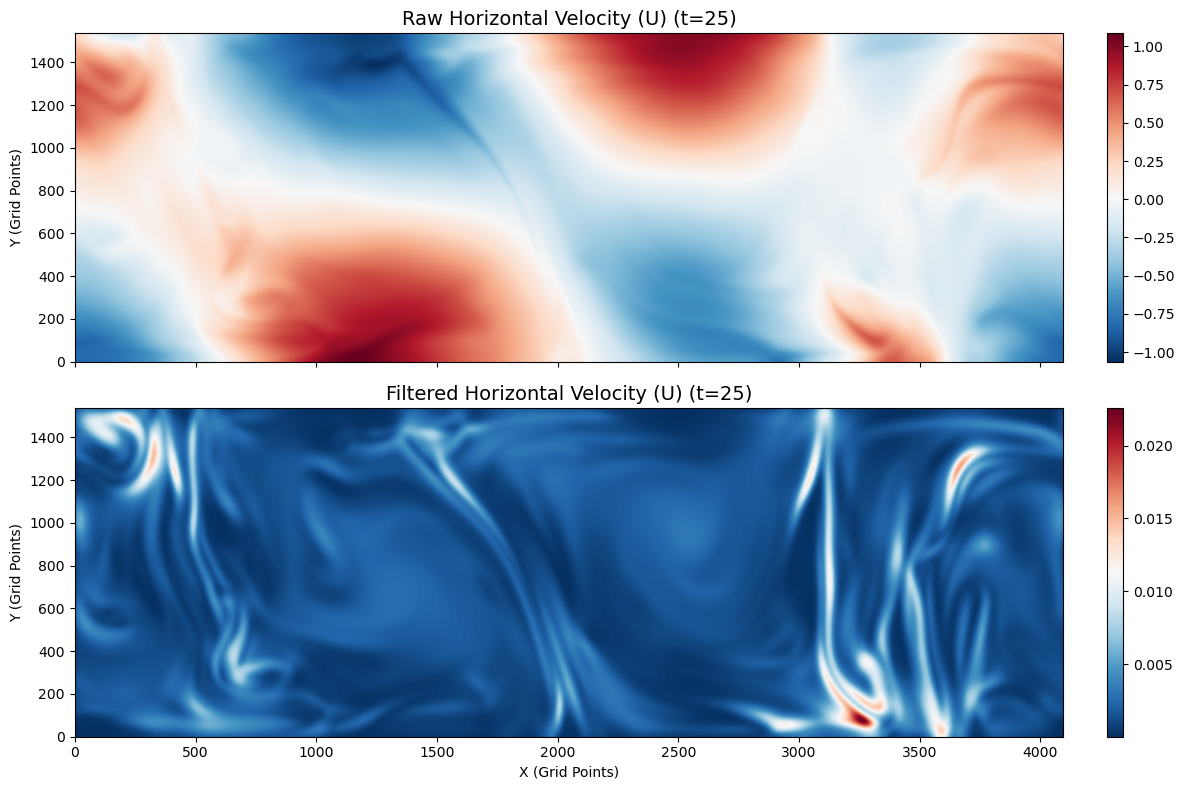

Zooming in on a small section...


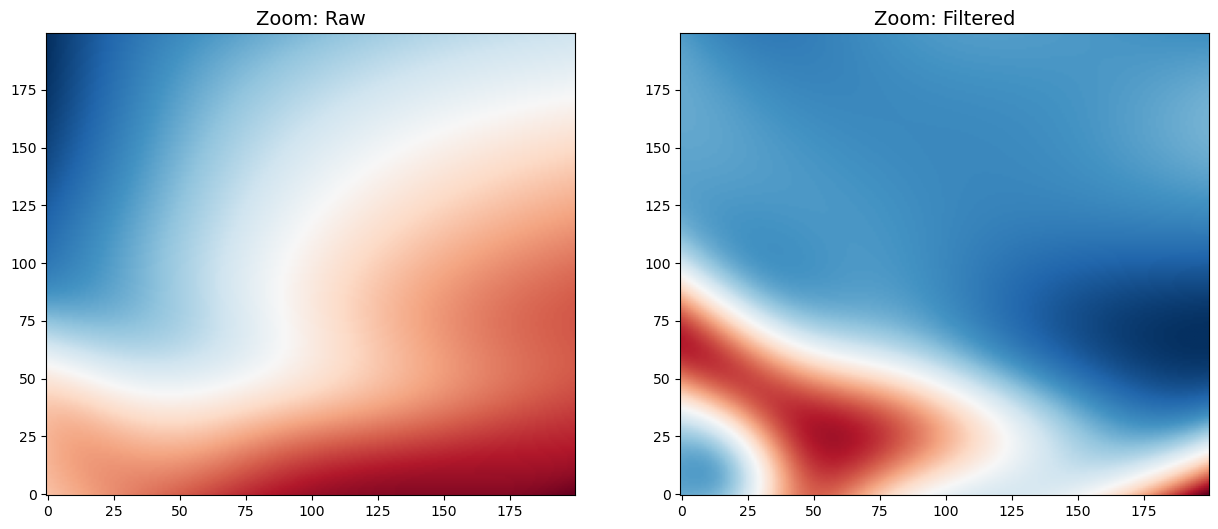

In [68]:
import matplotlib.pyplot as plt

# === Parameters ===
field_name = 'u'      # Choose: 'u', 'v', 'p', 'b', or 'w'
time_step_idx = 25    # Choose a timestep to visualize (e.g., 50)
cmap = 'RdBu_r'       # Colormap (Red-Blue is good for velocity/divergence)

# === Select Data ===
if field_name == 'u':
    raw_data = U[:, :, time_step_idx]
    filt_data = tau_xx[:, :, time_step_idx] + tau_yy[:, :, time_step_idx]
    title_txt = "Horizontal Velocity (U)"
elif field_name == 'v':
    raw_data = V[:, :, time_step_idx]
    filt_data = v_filt[:, :, time_step_idx]
    title_txt = "Vertical Velocity (V)"
elif field_name == 'b':
    raw_data = B[:, :, time_step_idx]
    filt_data = b_filt[:, :, time_step_idx]
    title_txt = "Buoyancy (B)"
elif field_name == 'p':
    raw_data = P[:, :, time_step_idx]
    filt_data = p_filt[:, :, time_step_idx]
    title_txt = "Pressure (P)"
elif field_name == 'w':
    raw_data = W[:, :, time_step_idx]
    filt_data = w_filt[:, :, time_step_idx]
    title_txt = "Vorticity (W)"

# === Plotting ===
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot Raw
# We transpose (.T) so that X is horizontal and Y is vertical
im1 = axes[0].imshow(raw_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title(f"Raw {title_txt} (t={time_step_idx})", fontsize=14)
axes[0].set_ylabel("Y (Grid Points)")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Plot Filtered
im2 = axes[1].imshow(filt_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title(f"Filtered {title_txt} (t={time_step_idx})", fontsize=14)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# === Optional: Zoom in to see the smoothing ===
# Use this to see the pixel-level difference
print("Zooming in on a small section...")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Zoom slice
ys, ye = 100, 300  # Y-slice
xs, xe = 1000, 1200 # X-slice

im3 = axes[0].imshow(raw_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title("Zoom: Raw", fontsize=14)

im4 = axes[1].imshow(filt_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title("Zoom: Filtered", fontsize=14)

plt.show()

Calculating Continuity Residuals (Divergence)...
Raw Divergence      - Mean: 2.291656e-04, Max: 4.623640e-02
Filtered Divergence - Mean: 2.504205e-04, Max: 8.139378e-02


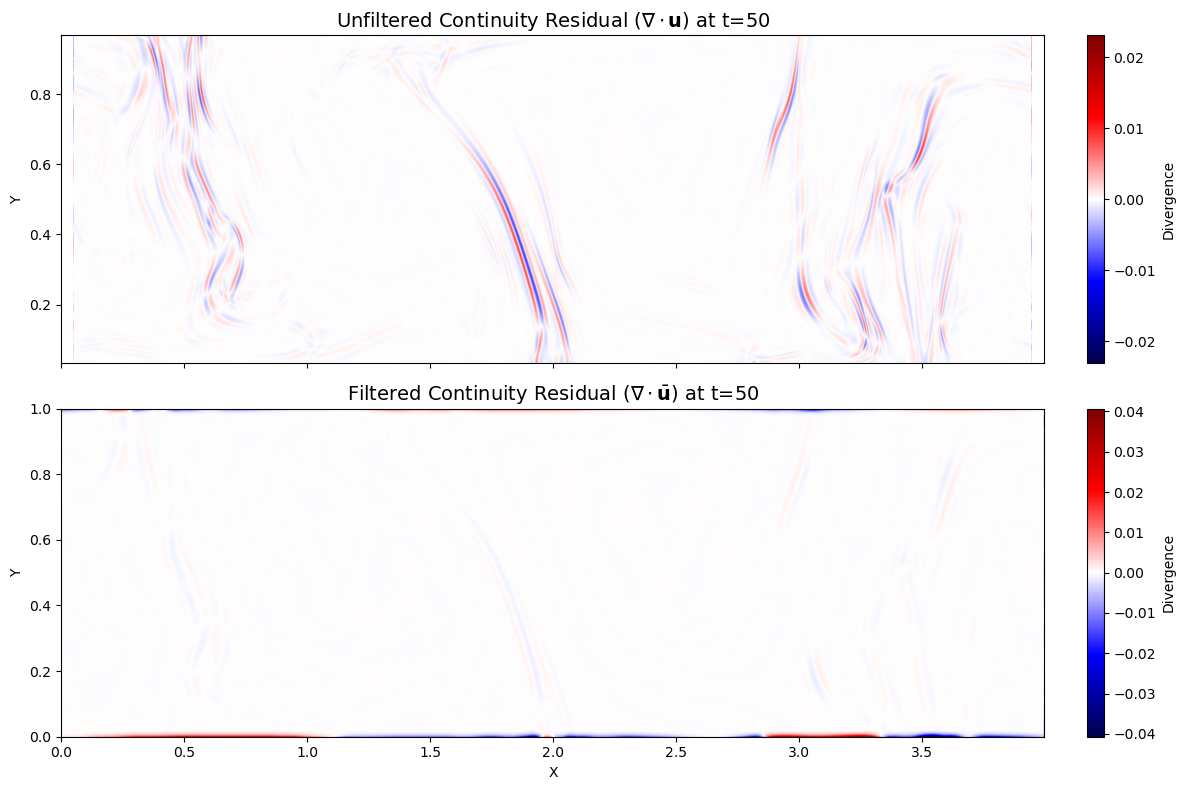

In [69]:
import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residuals (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original arrays
dx_raw = float(x[1] - x[0])
dy_raw = float(y[1] - y[0])

U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

du_dx_raw = np.gradient(U_raw_t, dx_raw, axis=0)
dv_dy_raw = np.gradient(V_raw_t, dy_raw, axis=1)
div_raw = du_dx_raw + dv_dy_raw
extent_raw = [x[0], x[-1], y[0], y[-1]]

# --- 2. Filtered Divergence ---
# u_filt, v_filt, xp, yp are the JAX filtered & trimmed arrays
dx_filt = float(xp[1] - xp[0])
dy_filt = float(yp[1] - yp[0])

u_filt_t = u_bar[:, :, t_idx,0]
v_filt_t = u_bar[:, :, t_idx,1]

du_dx_filt = np.gradient(u_filt_t, dx_filt, axis=0)
dv_dy_filt = np.gradient(v_filt_t, dy_filt, axis=1)
div_filt = du_dx_filt + dv_dy_filt
extent_filt = [xp[0], xp[-1], yp[0], yp[-1]]

print(f"Raw Divergence      - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Filtered Divergence - Mean: {np.mean(np.abs(div_filt)):.6e}, Max: {np.max(np.abs(div_filt)):.6e}")

# --- 3. 2x1 Plotting ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Set dynamic limits to show structure rather than noise outliers
v_limit_raw = np.max(np.abs(div_raw)) * 0.5 
v_limit_filt = np.max(np.abs(div_filt)) * 0.5

# Plot Raw
im1 = axes[0].imshow(
    div_raw.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_raw,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)
axes[0].set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
axes[0].set_ylabel("Y")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04, label="Divergence")

# Plot Filtered
im2 = axes[1].imshow(
    div_filt.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_filt,
    vmax=v_limit_filt
)
axes[1].set_title(f"Filtered Continuity Residual ($\\nabla \\cdot \\bar{{\\mathbf{{u}}}}$) at t={t_idx}", fontsize=14)
axes[1].set_ylabel("Y")
axes[1].set_xlabel("X")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label="Divergence")

plt.tight_layout()
plt.show()

In [70]:
'''import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residuals (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original arrays
dx_raw = float(x[1] - x[0])
dy_raw = float(y[1] - y[0])

U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

du_dx_raw = np.gradient(V_raw_t, dx_raw, axis=0)
dv_dy_raw = np.gradient(U_raw_t, dy_raw, axis=1)
div_raw = du_dx_raw + dv_dy_raw

# --- 2. Filtered Divergence ---
# u_filt, v_filt, xp, yp are the JAX filtered & trimmed arrays
dx_filt = float(xp[1] - xp[0])
dy_filt = float(yp[1] - yp[0])

u_filt_t = u_filt[:, :, t_idx]
v_filt_t = v_filt[:, :, t_idx]

du_dx_filt = np.gradient(u_filt_t, dx_filt, axis=0)
dv_dy_filt = np.gradient(v_filt_t, dy_filt, axis=1)
div_filt = du_dx_filt + dv_dy_filt
extent_filt = [xp[0], xp[-1], yp[0], yp[-1]]

# --- 3. Difference (Raw - Filtered) ---
# To subtract them, we must crop the raw data to match the filtered trimmed domain
x_mask = (x >= xp[0]) & (x <= xp[-1])
y_mask = (y >= yp[0]) & (y <= yp[-1])

# Apply the coordinate masks to get an identically shaped cropped array
div_raw_cropped = div_raw[np.ix_(x_mask, y_mask)]

# Calculate difference
div_diff = div_raw_cropped - div_filt

print(f"Raw Divergence (Full) - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Filtered Divergence   - Mean: {np.mean(np.abs(div_filt)):.6e}, Max: {np.max(np.abs(div_filt)):.6e}")
print(f"Difference            - Mean: {np.mean(np.abs(div_diff)):.6e}, Max: {np.max(np.abs(div_diff)):.6e}")

# --- 4. 3x1 Plotting ---
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# Set dynamic limits to show structure rather than noise outliers
v_limit_raw = np.max(np.abs(div_raw_cropped)) * 0.5 
v_limit_filt = np.max(np.abs(div_filt)) * 0.5
v_limit_diff = np.max(np.abs(div_diff)) * 0.5

# Plot Raw (Cropped visually to match)
im1 = axes[0].imshow(
    div_raw_cropped.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)
axes[0].set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
axes[0].set_ylabel("Y")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04, label="Divergence")

# Plot Filtered
im2 = axes[1].imshow(
    div_filt.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_filt,
    vmax=v_limit_filt
)
axes[1].set_title(f"Filtered Continuity Residual ($\\nabla \\cdot \\bar{{\\mathbf{{u}}}}$) at t={t_idx}", fontsize=14)
axes[1].set_ylabel("Y")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label="Divergence")

# Plot Difference
im3 = axes[2].imshow(
    div_diff.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_diff,
    vmax=v_limit_diff
)
axes[2].set_title(f"Difference (Raw - Filtered) at t={t_idx}", fontsize=14)
axes[2].set_ylabel("Y")
axes[2].set_xlabel("X")
plt.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04, label="Divergence Diff")

plt.tight_layout()
plt.show()'''

'import numpy as np\nimport matplotlib.pyplot as plt\n\nprint("Calculating Continuity Residuals (Divergence)...")\n\nt_idx = 50\ncmap = \'seismic\'\n\n# --- 1. Raw (Unfiltered) Divergence ---\n# U, V, x, y are original arrays\ndx_raw = float(x[1] - x[0])\ndy_raw = float(y[1] - y[0])\n\nU_raw_t = U[:, :, t_idx]\nV_raw_t = V[:, :, t_idx]\n\ndu_dx_raw = np.gradient(V_raw_t, dx_raw, axis=0)\ndv_dy_raw = np.gradient(U_raw_t, dy_raw, axis=1)\ndiv_raw = du_dx_raw + dv_dy_raw\n\n# --- 2. Filtered Divergence ---\n# u_filt, v_filt, xp, yp are the JAX filtered & trimmed arrays\ndx_filt = float(xp[1] - xp[0])\ndy_filt = float(yp[1] - yp[0])\n\nu_filt_t = u_filt[:, :, t_idx]\nv_filt_t = v_filt[:, :, t_idx]\n\ndu_dx_filt = np.gradient(u_filt_t, dx_filt, axis=0)\ndv_dy_filt = np.gradient(v_filt_t, dy_filt, axis=1)\ndiv_filt = du_dx_filt + dv_dy_filt\nextent_filt = [xp[0], xp[-1], yp[0], yp[-1]]\n\n# --- 3. Difference (Raw - Filtered) ---\n# To subtract them, we must crop the raw data to match the fil

In [7]:
print("omega:", np.mean(np.sqrt(w_filt**2)))
# Calculate RMS for both raw and filtered divergence
rms_div_raw = np.sqrt(np.mean(div_raw**2))
rms_div_filt = np.sqrt(np.mean(div_filt**2))

print(f"RMS Divergence (Raw):      {rms_div_raw:.6e}")
print(f"RMS Divergence (Filtered): {rms_div_filt:.6e}")

omega: 2.701274435287046


NameError: name 'div_raw' is not defined